# 01 — Build Municipal Heat-Pump Analysis Dataset

This notebook consolidates the municipality-level data preparation work used in the CELT Massachusetts heat-pump adoption project.

It preserves the original cleaning, merging, adoption-rate construction, heating-fuel processing, and year-comparison work. Because the original analysis evolved over time, some sections repeat or refine earlier steps; those are intentionally retained to preserve the research trail.


## Source provenance

This polished notebook consolidates the following original work:

- `build_town_tables.ipynb` — Original Python workflow for cleaning Mass Save installation data and ACS household/heating-fuel data and constructing municipality-level tables.
- `2013_electric_data_clean&merge.ipynb` — 2013 municipal electricity cleaning, winter/summer metrics, heat-pump merging, installs-per-1,000 calculations, and early exploratory correlations.
- `eda13_04(1).ipynb` — 2013/2023/2024 heating-fuel and heat-pump adoption integration and year-comparison analysis.

No analytical code from the source files was silently replaced. The purpose of this version is to make the workflow easier to follow in a public research repository.


---
## Original analysis section: `build_town_tables.ipynb`

**What this section contains:** Original Python workflow for cleaning Mass Save installation data and ACS household/heating-fuel data and constructing municipality-level tables.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [ ]:
import os
import re
import pandas as pd

RAW_DIR = "../data/raw"  # Update to your local data path
OUT_DIR = "../data/processed"
os.makedirs(OUT_DIR, exist_ok=True)

MASS_SAVE_FILE = os.path.join(RAW_DIR, "masssave_hp_raw.xlsx")  # Restricted: not included in repo
ACS_FILE       = os.path.join(RAW_DIR, "acs_households_clean.xlsx")

def clean_muni_name(x: str) -> str:
    if pd.isna(x):
        return x
    x = str(x).strip()
    x = re.sub(r"\s+", " ", x)
    return x

def coerce_numeric(series: pd.Series) -> pd.Series:
    return (
        series.astype(str)
        .str.replace(",", "", regex=False)
        .replace({"*": None, "nan": None, "None": None, "": None})
        .pipe(pd.to_numeric, errors="coerce")
    )

def find_col(df: pd.DataFrame, keywords: list[str]) -> str | None:
    for c in df.columns:
        cl = str(c).lower()
        if all(k in cl for k in keywords):
            return c
    return None

# ----------------------------
# 1) Mass Save installs
# ----------------------------
ms = pd.read_excel(MASS_SAVE_FILE)
print("Mass Save columns:", list(ms.columns))

ms_muni = find_col(ms, ["municipality"]) or find_col(ms, ["city"]) or ms.columns[0]
ms_accounts = find_col(ms, ["installed", "heat", "pump", "account"])
ms_locations = find_col(ms, ["installed", "heat", "pump", "location"])

if ms_accounts is None:
    raise ValueError("Couldn't find the 'Installed heat pumps (accounts)' column in Mass Save export.")

ms_cols = [ms_muni, ms_accounts] + ([ms_locations] if ms_locations else [])
ms_clean = ms[ms_cols].copy()
ms_clean.columns = ["municipality", "hp_accounts"] + (["hp_locations"] if ms_locations else [])

ms_clean["municipality"] = ms_clean["municipality"].apply(clean_muni_name)
ms_clean = ms_clean[~ms_clean["municipality"].str.lower().isin(["total", "unknown"])]

ms_clean["hp_accounts"] = coerce_numeric(ms_clean["hp_accounts"])
if "hp_locations" in ms_clean.columns:
    ms_clean["hp_locations"] = coerce_numeric(ms_clean["hp_locations"])

# ----------------------------
# 2) ACS households + fuel mix
# ----------------------------
acs = pd.read_excel(ACS_FILE)
print("ACS columns:", list(acs.columns))

acs_muni = find_col(acs, ["city"]) or find_col(acs, ["municipality"]) or acs.columns[0]
acs_households = find_col(acs, ["household", "income", "total"])  # total households column
acs_gas_service = find_col(acs, ["gas", "service", "territory"])
acs_delivered = find_col(acs, ["heating", "fuel", "delivered"])
acs_gas_fuel = find_col(acs, ["heating", "fuel", "gas"])
acs_elec_fuel = find_col(acs, ["heating", "fuel", "electric"])

missing = [name for name, val in {
    "Household income Total": acs_households,
    "Gas Service Territory": acs_gas_service,
    "Heating fuel Delivered fuels": acs_delivered,
    "Heating fuel gas": acs_gas_fuel,
    "Heating fuel Electricity": acs_elec_fuel,
}.items() if val is None]

if missing:
    raise ValueError(f"Missing expected columns in ACS export: {missing}")

acs_clean = acs[[acs_muni, acs_households, acs_gas_service, acs_delivered, acs_gas_fuel, acs_elec_fuel]].copy()
acs_clean.columns = ["municipality", "households", "gas_service", "delivered_fuels", "gas_fuel", "electric_fuel"]

acs_clean["municipality"] = acs_clean["municipality"].apply(clean_muni_name)
acs_clean = acs_clean[~acs_clean["municipality"].str.lower().isin(["total", "unknown"])]

for c in ["households", "delivered_fuels", "gas_fuel", "electric_fuel"]:
    acs_clean[c] = coerce_numeric(acs_clean[c])

# ----------------------------
# 3) Merge + compute metrics
# ----------------------------
df = ms_clean.merge(acs_clean, on="municipality", how="left", validate="1:1")

df["installs_per_1000"] = (df["hp_accounts"] / df["households"]) * 1000
df["delivered_share"] = df["delivered_fuels"] / df["households"]
df["gas_share"] = df["gas_fuel"] / df["households"]
df["electric_share"] = df["electric_fuel"] / df["households"]

df["hp_suppressed_or_missing"] = df["hp_accounts"].isna().astype(int)
df["acs_missing"] = df["households"].isna().astype(int)
df["no_gas_service_flag"] = df["gas_service"].astype(str).str.contains("no gas", case=False, na=False).astype(int)

df["oil_dominant_proxy"] = ((df["delivered_share"] > df["gas_share"]) & (df["no_gas_service_flag"] == 1)).astype(int)

# ----------------------------
# 4) Small towns definition: drop top 50 by households (size proxy)
# ----------------------------
df_size_sorted = df.dropna(subset=["households"]).sort_values("households", ascending=False)
top50_big = set(df_size_sorted.head(50)["municipality"].tolist())

df["is_big50"] = df["municipality"].isin(top50_big).astype(int)
df["is_small"] = (1 - df["is_big50"])

# ----------------------------
# 5) Rank small towns
# ----------------------------
small = df[(df["is_small"] == 1) & df["installs_per_1000"].notna()].copy()
small = small.sort_values("installs_per_1000", ascending=False)
small["rank_small_installs_per_1000"] = range(1, len(small) + 1)

# ----------------------------
# 6) Top / mid / bottom 20 (non-missing)
# ----------------------------
top20 = small.head(20).copy()

mid_start = max(len(small)//2 - 10, 0)
mid20 = small.iloc[mid_start:mid_start+20].copy()

bottom20 = small.tail(20).copy()

top20["adoption_group"] = "High"
mid20["adoption_group"] = "Medium"
bottom20["adoption_group"] = "Low"

groups = pd.concat([top20, mid20, bottom20], ignore_index=True)

# ----------------------------
# 7) Save deliverables
# ----------------------------
df.to_csv(os.path.join(OUT_DIR, "town_adoption_master.csv"), index=False)
small.to_csv(os.path.join(OUT_DIR, "small_towns_ranked_by_installs_per_1000.csv"), index=False)
top20.to_csv(os.path.join(OUT_DIR, "top20_small_high_adoption.csv"), index=False)
mid20.to_csv(os.path.join(OUT_DIR, "mid20_small_medium_adoption.csv"), index=False)
bottom20.to_csv(os.path.join(OUT_DIR, "bottom20_small_low_adoption.csv"), index=False)
groups.to_csv(os.path.join(OUT_DIR, "adoption_groups_high_med_low_60towns.csv"), index=False)

summary = groups.groupby("adoption_group")[["installs_per_1000", "delivered_share", "gas_share", "no_gas_service_flag"]].mean()
print("\n✅ Saved outputs to:", OUT_DIR)
print("\nQuick group means (sanity check):\n", summary.round(3))
print("\nTop 10 small towns by installs_per_1000:\n", small[["municipality","installs_per_1000","hp_accounts","households","delivered_share","gas_share","no_gas_service_flag"]].head(10))


---
## Original analysis section: `2013_electric_data_clean&merge.ipynb`

**What this section contains:** 2013 municipal electricity cleaning, winter/summer metrics, heat-pump merging, installs-per-1,000 calculations, and early exploratory correlations.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
import pandas as pd
import numpy as np

# =========================
# 1. Load the Excel file
# =========================
file_path = "data2013.xlsx"
df = pd.read_excel(file_path)

print("Original shape:", df.shape)
print(df.head())

# =========================
# 2. Rename first two columns
# =========================
# Your sheet shows:
# col A = municipality
# col B = sector
# Then Jan...Dec...Total

df = df.rename(columns={
    df.columns[0]: "municipality",
    df.columns[1]: "sector"
})

print("\nColumns after renaming first two:")
print(df.columns.tolist())

# =========================
# 3. Keep only TOTAL rows
# =========================
df = df[df["sector"].astype(str).str.strip().eq("Total")].copy()

# Remove aggregate statewide row
df = df[~df["municipality"].astype(str).str.contains("All Municipalities", case=False, na=False)].copy()

print("\nShape after keeping Total rows only:", df.shape)

# =========================
# 4. Clean municipality names
# =========================
df["municipality"] = (
    df["municipality"]
    .astype(str)
    .str.strip()
)

# =========================
# 5. Identify month columns
# =========================
# Based on your sheet:
# Jan is column 3, Feb 4, ... Dec 14, Total 15
# But safer to refer by position after first two columns

month_cols = list(df.columns[2:14])   # Jan to Dec
annual_col = df.columns[14]           # Total annual column

print("\nMonth columns detected:")
print(month_cols)
print("Annual column detected:", annual_col)

# Rename months to standard names for clarity
rename_map = {
    month_cols[0]: "Jan",
    month_cols[1]: "Feb",
    month_cols[2]: "Mar",
    month_cols[3]: "Apr",
    month_cols[4]: "May",
    month_cols[5]: "Jun",
    month_cols[6]: "Jul",
    month_cols[7]: "Aug",
    month_cols[8]: "Sep",
    month_cols[9]: "Oct",
    month_cols[10]: "Nov",
    month_cols[11]: "Dec",
    annual_col: "Annual_MWh"
}
df = df.rename(columns=rename_map)

# =========================
# 6. Convert numeric columns
# =========================
# Handle commas and "Protected"
value_cols = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec","Annual_MWh"]

for col in value_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .replace("Protected", np.nan)
        .replace("protected", np.nan)
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

# =========================
# 7. Compute winter/summer metrics
# =========================
# Winter = Dec + Jan + Feb
# Summer = Jun + Jul + Aug

df["Winter_MWh"] = df["Dec"] + df["Jan"] + df["Feb"]
df["Summer_MWh"] = df["Jun"] + df["Jul"] + df["Aug"]

# Avoid divide-by-zero
df["Winter_Summer_Ratio"] = np.where(
    df["Summer_MWh"] > 0,
    df["Winter_MWh"] / df["Summer_MWh"],
    np.nan
)

# Optional: highest winter month / average summer month
df["Highest_Winter_Month"] = df[["Dec", "Jan", "Feb"]].max(axis=1)
df["Summer_Avg_MWh"] = df[["Jun", "Jul", "Aug"]].mean(axis=1)
df["Highest_Winter_Month_Ratio"] = np.where(
    df["Summer_Avg_MWh"] > 0,
    df["Highest_Winter_Month"] / df["Summer_Avg_MWh"],
    np.nan
)

# =========================
# 8. Final clean output
# =========================
result = df[[
    "municipality",
    "Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec",
    "Annual_MWh",
    "Winter_MWh",
    "Summer_MWh",
    "Winter_Summer_Ratio",
    "Highest_Winter_Month",
    "Summer_Avg_MWh",
    "Highest_Winter_Month_Ratio"
]].copy()

# Sort by winter/summer ratio descending
result_sorted = result.sort_values("Winter_Summer_Ratio", ascending=False)

print("\nTop 20 towns by Winter/Summer Ratio:")
print(result_sorted[["municipality", "Winter_MWh", "Summer_MWh", "Winter_Summer_Ratio"]].head(20))

print("\nTop 20 towns by Highest Winter Month Ratio:")
print(result_sorted.sort_values("Highest_Winter_Month_Ratio", ascending=False)[
    ["municipality", "Highest_Winter_Month", "Summer_Avg_MWh", "Highest_Winter_Month_Ratio"]
].head(20))

# =========================
# 9. Save outputs
# =========================
result.to_csv("electricity_2013_clean_with_ratios.csv", index=False)
result_sorted.to_csv("electricity_2013_ranked_by_winter_summer_ratio.csv", index=False)

print("\nSaved files:")
print("1. electricity_2013_clean_with_ratios.csv")
print("2. electricity_2013_ranked_by_winter_summer_ratio.csv")

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Original shape: (1059, 15)
        Month - short                Unnamed: 1                  Jan  \
0        Municipality                    Sector  _consumption_static   
1  All Municipalities                     Total              3885632   
2  All Municipalities  Residential & Low Income              1348265   
3  All Municipalities   Commercial & Industrial              2537367   
4            Abington                     Total                 7535   

                   Feb                  Mar                  Apr  \
0  _consumption_static  _consumption_static  _consumption_static   
1              3529356              3658776              3369857   
2              1328769              1313205              1114809   
3              2200587              2345571              2255048   
4                 6971                 7315                 6292   

                   May                  Jun                  Jul  \
0  _consumption_static  _consumption_static  _consumption_stati

In [2]:
high_winter = result_sorted[result_sorted["Winter_Summer_Ratio"] > 1]
print("Number of towns with Winter/Summer Ratio > 1:", high_winter.shape[0])
print(high_winter[["municipality", "Winter_Summer_Ratio"]].head(30))

Number of towns with Winter/Summer Ratio > 1: 111
     municipality  Winter_Summer_Ratio
364       Hancock             2.579768
163    Charlemont             1.677205
940    Washington             1.623301
781   Sandisfield             1.528114
1036      Windsor             1.377729
571        Monroe             1.360976
103     Blandford             1.330088
43       Ashfield             1.325634
298       Florida             1.313196
691        Pelham             1.310266
790         Savoy             1.294118
712    Plainfield             1.275362
274      Egremont             1.267327
958       Wendell             1.262125
901         Truro             1.258974
73        Bedford             1.253243
466     Lexington             1.250784
391         Heath             1.244248
70         Becket             1.243590
937       Warwick             1.240169
817    Shutesbury             1.235259
211    Cummington             1.230198
757      Rockport             1.227357
145      Buckl

In [4]:
import pandas as pd

# electricity dataset you created earlier
elec = pd.read_csv("../data/processed/electricity_2013_clean_with_ratios.csv")

# heat pump dataset
hp = pd.read_csv("../data/processed/masssave_heat_pumps_clean.csv  # Restricted: contact research team for access")

print("Electricity dataset:", elec.shape)
print("Heat pump dataset:", hp.shape)

elec.head()

Electricity dataset: (351, 20)
Heat pump dataset: (348, 3)


,municipality,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio
0,Abington,7535.0,6971.0,7315.0,6292.0,6652.0,7832.0,8961.0,8201.0,6724.0,6518.0,7090.0,8434.0,88525.0,22940.0,24994.0,0.917820,8434.0,8331.333333,1.012323
1,Acton,15183.0,13720.0,12662.0,12212.0,12278.0,13572.0,17292.0,13668.0,12992.0,12460.0,8953.0,19662.0,164654.0,48565.0,44532.0,1.090564,19662.0,14844.000000,1.324576
2,Acushnet,2668.0,2854.0,2994.0,2735.0,3170.0,3957.0,4973.0,4346.0,3472.0,3200.0,3299.0,3966.0,41634.0,9488.0,13276.0,0.714673,3966.0,4425.333333,0.896204
3,Adams,8306.0,7501.0,8080.0,7204.0,7421.0,7612.0,8301.0,7739.0,7303.0,7578.0,7597.0,8273.0,92915.0,24080.0,23652.0,1.018096,8306.0,7884.000000,1.053526
4,Agawam,20716.0,18371.0,19385.0,17554.0,19648.0,22671.0,26594.0,24230.0,18967.0,17909.0,18241.0,22348.0,246634.0,61435.0,73495.0,0.835907,22348.0,24498.333333,0.912225


In [5]:
print(elec.columns)
print(hp.columns)

Index(['municipality', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug',
       'Sep', 'Oct', 'Nov', 'Dec', 'Annual_MWh', 'Winter_MWh', 'Summer_MWh',
       'Winter_Summer_Ratio', 'Highest_Winter_Month', 'Summer_Avg_MWh',
       'Highest_Winter_Month_Ratio'],
      dtype='object')
Index(['Municipality', 'Installed heat pumps (accounts)',
       'Installed heat pumps (locations)'],
      dtype='object')


In [6]:
hp = hp.rename(columns={
    "Municipality": "municipality",
    "Installed heat pumps (accounts)": "hp_accounts",
    "Installed heat pumps (locations)": "hp_locations"
})

In [7]:
print(hp.columns)

Index(['municipality', 'hp_accounts', 'hp_locations'], dtype='object')


In [8]:
elec["municipality"] = elec["municipality"].str.strip().str.title()
hp["municipality"] = hp["municipality"].str.strip().str.title()

In [9]:
merged = elec.merge(
    hp,
    on="municipality",
    how="left"
)

print("Merged dataset shape:", merged.shape)
merged.head()

Merged dataset shape: (351, 22)


,municipality,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,...,Dec,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,hp_locations
0,Abington,7535.0,6971.0,7315.0,6292.0,6652.0,7832.0,8961.0,8201.0,6724.0,...,8434.0,88525.0,22940.0,24994.0,0.917820,8434.0,8331.333333,1.012323,209.0,202.0
1,Acton,15183.0,13720.0,12662.0,12212.0,12278.0,13572.0,17292.0,13668.0,12992.0,...,19662.0,164654.0,48565.0,44532.0,1.090564,19662.0,14844.000000,1.324576,780.0,765.0
2,Acushnet,2668.0,2854.0,2994.0,2735.0,3170.0,3957.0,4973.0,4346.0,3472.0,...,3966.0,41634.0,9488.0,13276.0,0.714673,3966.0,4425.333333,0.896204,213.0,208.0
3,Adams,8306.0,7501.0,8080.0,7204.0,7421.0,7612.0,8301.0,7739.0,7303.0,...,8273.0,92915.0,24080.0,23652.0,1.018096,8306.0,7884.000000,1.053526,105.0,100.0
4,Agawam,20716.0,18371.0,19385.0,17554.0,19648.0,22671.0,26594.0,24230.0,18967.0,...,22348.0,246634.0,61435.0,73495.0,0.835907,22348.0,24498.333333,0.912225,332.0,329.0


In [10]:
merged.sort_values(
    "Winter_Summer_Ratio",
    ascending=False
)[["municipality","Winter_Summer_Ratio","hp_accounts"]].head(20)

,municipality,Winter_Summer_Ratio,hp_accounts
120,Hancock,2.579768,NaN
53,Charlemont,1.677205,NaN
312,Washington,1.623301,NaN
259,Sandisfield,1.528114,NaN
344,Windsor,1.377729,NaN
189,Monroe,1.360976,NaN
33,Blandford,1.330088,NaN
13,Ashfield,1.325634,NaN
98,Florida,1.313196,NaN
229,Pelham,1.310266,114.0


In [11]:
merged["Winter_Summer_Ratio"].corr(merged["hp_accounts"])

np.float64(-0.1345755977432563)

In [12]:
merged.to_csv("electricity2013_heatpump_merged.csv", index=False)

In [13]:
import pandas as pd

elec = pd.read_csv("../data/processed/electricity_2013_clean_with_ratios.csv")

hp = pd.read_csv("../data/processed/ma_heatpump_installs_per_1000_all_towns.csv  # Derived from restricted data")

# standardize municipality names
elec["municipality"] = elec["municipality"].str.strip().str.lower()
hp["municipality"] = hp["municipality"].str.strip().str.lower()

# merge
merged = elec.merge(
    hp,
    on="municipality",
    how="left"
)

print(merged.shape)
merged.head()

(351, 27)


,municipality,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,...,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,hp_locations,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
0,abington,7535.0,6971.0,7315.0,6292.0,6652.0,7832.0,8961.0,8201.0,6724.0,...,8434.0,8331.333333,1.012323,209.0,202.0,6438.0,1053.0,2774.0,2570.0,32.463498
1,acton,15183.0,13720.0,12662.0,12212.0,12278.0,13572.0,17292.0,13668.0,12992.0,...,19662.0,14844.000000,1.324576,780.0,765.0,9085.0,1483.0,4787.0,2815.0,85.855806
2,acushnet,2668.0,2854.0,2994.0,2735.0,3170.0,3957.0,4973.0,4346.0,3472.0,...,3966.0,4425.333333,0.896204,213.0,208.0,4103.0,148.0,1758.0,2066.0,51.913234
3,adams,8306.0,7501.0,8080.0,7204.0,7421.0,7612.0,8301.0,7739.0,7303.0,...,8306.0,7884.000000,1.053526,105.0,100.0,4081.0,333.0,2156.0,1547.0,25.728988
4,agawam,20716.0,18371.0,19385.0,17554.0,19648.0,22671.0,26594.0,24230.0,18967.0,...,22348.0,24498.333333,0.912225,332.0,329.0,11792.0,2154.0,6512.0,3023.0,28.154681


In [15]:
cols_to_drop = [
"Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec",
"hp_locations"
]

merged_clean = merged.drop(columns=cols_to_drop)

merged_clean.head()

,municipality,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
0,abington,88525.0,22940.0,24994.0,0.917820,8434.0,8331.333333,1.012323,209.0,6438.0,1053.0,2774.0,2570.0,32.463498
1,acton,164654.0,48565.0,44532.0,1.090564,19662.0,14844.000000,1.324576,780.0,9085.0,1483.0,4787.0,2815.0,85.855806
2,acushnet,41634.0,9488.0,13276.0,0.714673,3966.0,4425.333333,0.896204,213.0,4103.0,148.0,1758.0,2066.0,51.913234
3,adams,92915.0,24080.0,23652.0,1.018096,8306.0,7884.000000,1.053526,105.0,4081.0,333.0,2156.0,1547.0,25.728988
4,agawam,246634.0,61435.0,73495.0,0.835907,22348.0,24498.333333,0.912225,332.0,11792.0,2154.0,6512.0,3023.0,28.154681


In [16]:
merged_clean.to_csv("ma_heatpump_final_analysis_dataset.csv", index=False)

In [17]:
import pandas as pd

df = pd.read_csv("ma_heatpump_final_analysis_dataset.csv")

df.head()

,municipality,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
0,abington,88525.0,22940.0,24994.0,0.917820,8434.0,8331.333333,1.012323,209.0,6438.0,1053.0,2774.0,2570.0,32.463498
1,acton,164654.0,48565.0,44532.0,1.090564,19662.0,14844.000000,1.324576,780.0,9085.0,1483.0,4787.0,2815.0,85.855806
2,acushnet,41634.0,9488.0,13276.0,0.714673,3966.0,4425.333333,0.896204,213.0,4103.0,148.0,1758.0,2066.0,51.913234
3,adams,92915.0,24080.0,23652.0,1.018096,8306.0,7884.000000,1.053526,105.0,4081.0,333.0,2156.0,1547.0,25.728988
4,agawam,246634.0,61435.0,73495.0,0.835907,22348.0,24498.333333,0.912225,332.0,11792.0,2154.0,6512.0,3023.0,28.154681


In [18]:
df.describe()

,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
count,2.930000e+02,2.930000e+02,2.930000e+02,293.000000,293.000000,293.000000,293.000000,248.000000,344.000000,344.000000,344.000000,344.000000,248.000000
mean,1.569424e+05,4.060758e+04,4.377599e+04,0.981956,15515.351536,14591.995449,1.096886,444.741935,7914.148256,1415.284884,4101.979651,2265.436047,74.310732
std,4.226072e+05,1.132404e+05,1.162917e+05,0.189335,46420.755529,38763.894248,0.226560,429.503204,17426.657264,5059.020408,10272.482181,2318.028748,51.794020
min,9.150000e+02,2.790000e+02,2.050000e+02,0.556992,105.000000,68.333333,0.605892,101.000000,55.000000,2.000000,0.000000,53.000000,3.966590
25%,2.446300e+04,6.417000e+03,6.880000e+03,0.876715,2389.000000,2293.333333,0.954589,202.000000,1621.250000,143.500000,120.500000,845.500000,39.676077
50%,7.211400e+04,1.875200e+04,2.038500e+04,0.943088,6921.000000,6795.000000,1.058740,324.000000,4137.000000,448.000000,1409.000000,1816.500000,64.059188
75%,1.559040e+05,4.008600e+04,4.453200e+04,1.072877,14489.000000,14844.000000,1.200406,550.000000,8910.500000,1210.250000,4863.000000,2942.500000,93.319058
max,6.543473e+06,1.777120e+06,1.795215e+06,2.579768,740652.000000,598405.000000,3.049180,4471.000000,279216.000000,85739.000000,159684.000000,27690.000000,387.464387


In [19]:
df[[
    "installs_per_1000",
    "Winter_Summer_Ratio",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]].corr()

,installs_per_1000,Winter_Summer_Ratio,electric_fuel,gas_fuel,delivered_fuels
installs_per_1000,1.000000,0.102225,-0.212956,-0.302236,-0.331344
Winter_Summer_Ratio,0.102225,1.000000,-0.064747,-0.138183,-0.201811
electric_fuel,-0.212956,-0.064747,1.000000,0.954954,0.783106
gas_fuel,-0.302236,-0.138183,0.954954,1.000000,0.780760
delivered_fuels,-0.331344,-0.201811,0.783106,0.780760,1.000000


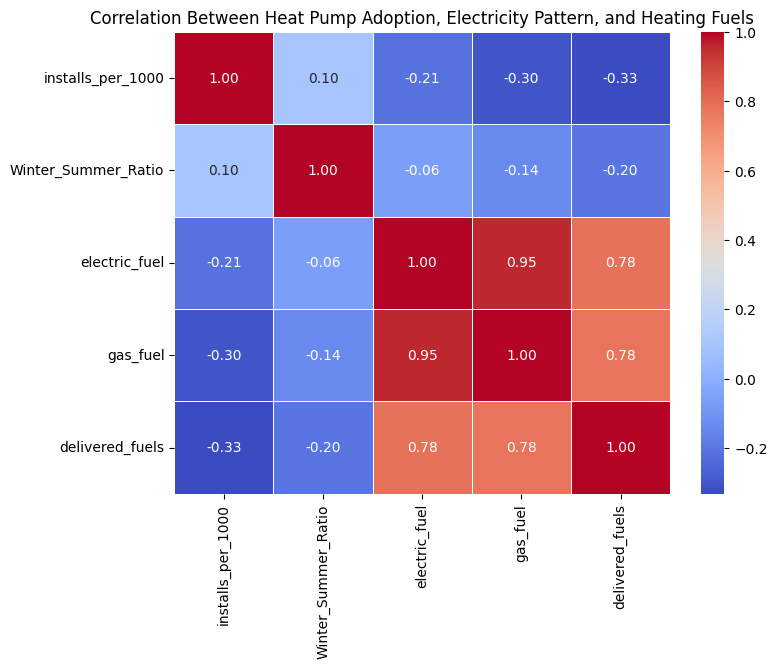

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# select variables
cols = [
    "installs_per_1000",
    "Winter_Summer_Ratio",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]

corr = df[cols].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Heat Pump Adoption, Electricity Pattern, and Heating Fuels")
plt.show()

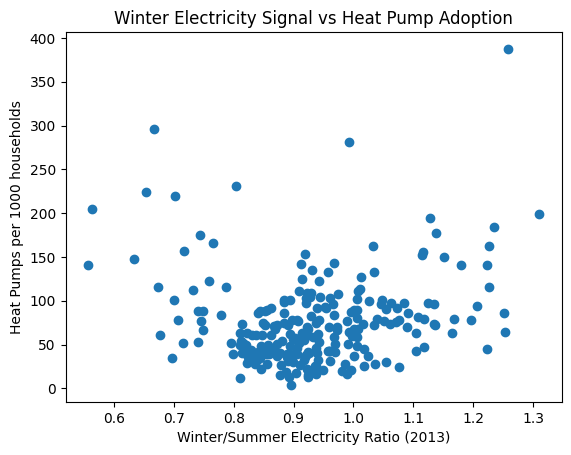

In [20]:
import matplotlib.pyplot as plt

plt.scatter(df["Winter_Summer_Ratio"], df["installs_per_1000"])
plt.xlabel("Winter/Summer Electricity Ratio (2013)")
plt.ylabel("Heat Pumps per 1000 households")
plt.title("Winter Electricity Signal vs Heat Pump Adoption")
plt.show()

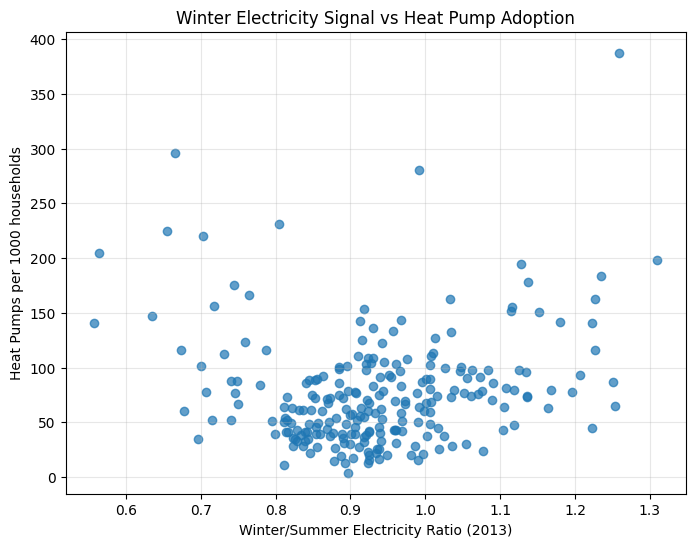

In [32]:
plt.figure(figsize=(8,6))
plt.scatter(df["Winter_Summer_Ratio"], df["installs_per_1000"], alpha=0.7)

plt.xlabel("Winter/Summer Electricity Ratio (2013)")
plt.ylabel("Heat Pumps per 1000 households")
plt.title("Winter Electricity Signal vs Heat Pump Adoption")

plt.grid(alpha=0.3)

plt.show()

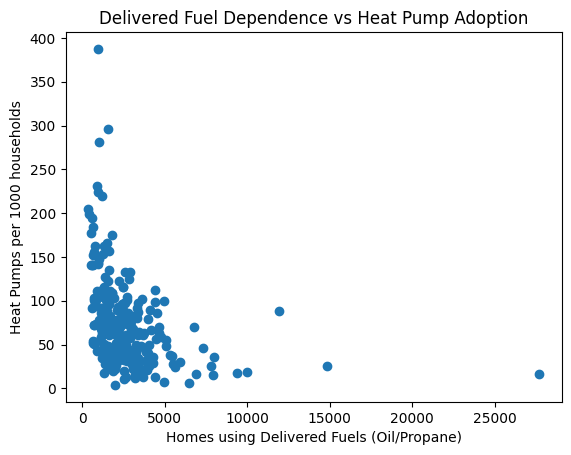

In [21]:
plt.scatter(df["delivered_fuels"], df["installs_per_1000"])
plt.xlabel("Homes using Delivered Fuels (Oil/Propane)")
plt.ylabel("Heat Pumps per 1000 households")
plt.title("Delivered Fuel Dependence vs Heat Pump Adoption")
plt.show()

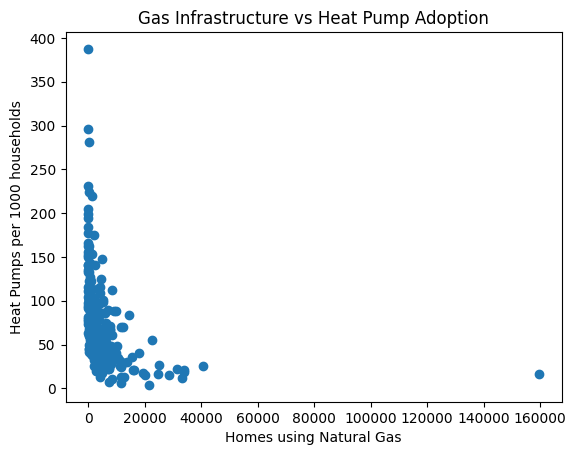

In [22]:
plt.scatter(df["gas_fuel"], df["installs_per_1000"])
plt.xlabel("Homes using Natural Gas")
plt.ylabel("Heat Pumps per 1000 households")
plt.title("Gas Infrastructure vs Heat Pump Adoption")
plt.show()

In [23]:
df.sort_values(
    "installs_per_1000",
    ascending=False
)[["municipality","installs_per_1000","delivered_fuels","gas_fuel"]].head(20)

,municipality,installs_per_1000,delivered_fuels,gas_fuel
299,truro,387.464387,979.0,41.0
317,wellfleet,295.738046,1580.0,72.0
241,provincetown,280.727630,1016.0,446.0
326,west tisbury,231.270358,889.0,0.0
89,edgartown,224.489796,999.0,174.0
86,eastham,219.930070,1214.0,1170.0
62,chilmark,205.035971,375.0,21.0
229,pelham,198.606272,436.0,19.0
153,leverett,194.677871,618.0,26.0
271,shutesbury,183.968462,653.0,20.0


In [24]:
df.sort_values(
    "installs_per_1000"
)[["municipality","installs_per_1000","delivered_fuels","gas_fuel"]].head(20)

,municipality,installs_per_1000,delivered_fuels,gas_fuel
148,lawrence,3.966590,2028.0,21414.0
228,peabody,6.275313,6458.0,11562.0
40,braintree,7.043727,4995.0,7388.0
219,norwood,10.376720,2547.0,8472.0
95,fall river,11.367172,3187.0,33240.0
93,everett,12.570965,2680.0,11469.0
247,revere,12.597620,3696.0,12747.0
245,reading,13.056194,4418.0,4282.0
159,lowell,14.911639,3212.0,28538.0
162,lynn,15.387580,7928.0,20133.0


In [25]:
small_towns = df[df["households"] < 20000]

In [26]:
small_towns.sort_values(
    "installs_per_1000",
    ascending=False
).head(20)

,municipality,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
299,truro,18866.0,4910.0,3900.0,1.258974,1745.0,1300.000000,1.342308,408.0,1053.0,23.0,41.0,979.0,387.464387
317,wellfleet,25090.0,5590.0,8392.0,0.666111,2042.0,2797.333333,0.729981,569.0,1924.0,236.0,72.0,1580.0,295.738046
241,provincetown,41498.0,10561.0,10647.0,0.991923,3642.0,3549.000000,1.026205,571.0,2034.0,463.0,446.0,1016.0,280.727630
326,west tisbury,24463.0,6075.0,7557.0,0.803890,2246.0,2519.000000,0.891624,213.0,921.0,32.0,0.0,889.0,231.270358
89,edgartown,63923.0,14723.0,22503.0,0.654268,5291.0,7501.000000,0.705373,374.0,1666.0,493.0,174.0,999.0,224.489796
86,eastham,38574.0,9104.0,12955.0,0.702740,3187.0,4318.333333,0.738016,629.0,2860.0,463.0,1170.0,1214.0,219.930070
62,chilmark,14520.0,3040.0,5397.0,0.563276,1090.0,1799.000000,0.605892,114.0,556.0,139.0,21.0,375.0,205.035971
229,pelham,5482.0,1723.0,1315.0,1.310266,681.0,438.333333,1.553612,114.0,574.0,111.0,19.0,436.0,198.606272
153,leverett,9136.0,2564.0,2273.0,1.128025,898.0,757.666667,1.185218,139.0,714.0,55.0,26.0,618.0,194.677871
271,shutesbury,6954.0,2053.0,1662.0,1.235259,763.0,554.000000,1.377256,140.0,761.0,67.0,20.0,653.0,183.968462


In [27]:
df["adoption_group"] = pd.qcut(
    df["installs_per_1000"],
    q=3,
    labels=["Low adoption","Medium adoption","High adoption"]
)

df.groupby("adoption_group")["installs_per_1000"].mean()

/tmp/ipykernel_186/1735759369.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("adoption_group")["installs_per_1000"].mean()


,installs_per_1000
adoption_group,
Low adoption,29.944070
Medium adoption,64.518812
High adoption,128.351339


In [28]:
df.groupby("adoption_group")[[
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]].mean()

/tmp/ipykernel_186/1498208258.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("adoption_group")[[


,electric_fuel,gas_fuel,delivered_fuels
adoption_group,,,
Low adoption,3871.240964,10830.951807,3697.638554
Medium adoption,945.402439,3293.780488,2438.317073
High adoption,595.120482,1764.578313,1912.361446


In [29]:
study_towns = small_towns.sort_values(
    "installs_per_1000",
    ascending=False
)

study_towns.head(10)

,municipality,Annual_MWh,Winter_MWh,Summer_MWh,Winter_Summer_Ratio,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
299,truro,18866.0,4910.0,3900.0,1.258974,1745.0,1300.000000,1.342308,408.0,1053.0,23.0,41.0,979.0,387.464387
317,wellfleet,25090.0,5590.0,8392.0,0.666111,2042.0,2797.333333,0.729981,569.0,1924.0,236.0,72.0,1580.0,295.738046
241,provincetown,41498.0,10561.0,10647.0,0.991923,3642.0,3549.000000,1.026205,571.0,2034.0,463.0,446.0,1016.0,280.727630
326,west tisbury,24463.0,6075.0,7557.0,0.803890,2246.0,2519.000000,0.891624,213.0,921.0,32.0,0.0,889.0,231.270358
89,edgartown,63923.0,14723.0,22503.0,0.654268,5291.0,7501.000000,0.705373,374.0,1666.0,493.0,174.0,999.0,224.489796
86,eastham,38574.0,9104.0,12955.0,0.702740,3187.0,4318.333333,0.738016,629.0,2860.0,463.0,1170.0,1214.0,219.930070
62,chilmark,14520.0,3040.0,5397.0,0.563276,1090.0,1799.000000,0.605892,114.0,556.0,139.0,21.0,375.0,205.035971
229,pelham,5482.0,1723.0,1315.0,1.310266,681.0,438.333333,1.553612,114.0,574.0,111.0,19.0,436.0,198.606272
153,leverett,9136.0,2564.0,2273.0,1.128025,898.0,757.666667,1.185218,139.0,714.0,55.0,26.0,618.0,194.677871
271,shutesbury,6954.0,2053.0,1662.0,1.235259,763.0,554.000000,1.377256,140.0,761.0,67.0,20.0,653.0,183.968462


---
## Original analysis section: `eda13_04(1).ipynb`

**What this section contains:** 2013/2023/2024 heating-fuel and heat-pump adoption integration and year-comparison analysis.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving fuel_2023_clean.csv to fuel_2023_clean.csv


In [2]:
from google.colab import files
uploaded = files.upload()

Saving fuel_2024_clean.csv to fuel_2024_clean.csv


In [3]:
from google.colab import files
uploaded = files.upload()

Saving heat_pumps_clean.csv to heat_pumps_clean.csv


In [4]:
import pandas as pd
import numpy as np


In [6]:
fuel_2023 = pd.read_csv('fuel_2023_clean.csv')
fuel_2024 = pd.read_csv('fuel_2024_clean.csv')
heat_pumps = pd.read_csv('heat_pumps_clean.csv')

In [7]:
print("fuel_2023 columns:", fuel_2023.columns.tolist())
print("fuel_2024 columns:", fuel_2024.columns.tolist())
print("heat_pumps columns:", heat_pumps.columns.tolist())


fuel_2023 columns: ['municipality', 'geo_id', 'total_households', 'electric_fuel', 'gas_fuel', 'delivered_fuels', 'electric_share', 'gas_share', 'delivered_share']
fuel_2024 columns: ['municipality', 'geo_id', 'total_households', 'electric_fuel', 'gas_fuel', 'delivered_fuels', 'electric_share', 'gas_share', 'delivered_share']
heat_pumps columns: ['municipality', 'heat_pump_installs']


In [8]:
# ================================
# 5. CLEAN MUNICIPALITY NAMES
# ================================
def clean_municipality(df, col="municipality"):
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )
    return df

fuel_2023 = clean_municipality(fuel_2023, "municipality")
fuel_2024 = clean_municipality(fuel_2024, "municipality")
heat_pumps = clean_municipality(heat_pumps, "municipality")

In [9]:
# ================================
# 6. MAKE SURE NUMERIC COLUMNS ARE NUMERIC
# ================================
fuel_numeric_cols = [
    "total_households",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels",
    "electric_share",
    "gas_share",
    "delivered_share"
]

for col in fuel_numeric_cols:
    if col in fuel_2023.columns:
        fuel_2023[col] = pd.to_numeric(fuel_2023[col], errors="coerce")
    if col in fuel_2024.columns:
        fuel_2024[col] = pd.to_numeric(fuel_2024[col], errors="coerce")

heat_pumps["heat_pump_installs"] = pd.to_numeric(
    heat_pumps["heat_pump_installs"], errors="coerce"
)

In [10]:
# ================================
# 7. QUICK SHAPE CHECK
# ================================
print("fuel_2023 shape:", fuel_2023.shape)
print("fuel_2024 shape:", fuel_2024.shape)
print("heat_pumps shape:", heat_pumps.shape)

fuel_2023 shape: (351, 9)
fuel_2024 shape: (351, 9)
heat_pumps shape: (345, 2)


In [11]:
# ================================
# 8. MERGE HEAT PUMPS INTO FUEL 2023
# ================================
merged_2023 = fuel_2023.merge(
    heat_pumps,
    on="municipality",
    how="left"
)

# create installs_per_1000
merged_2023["installs_per_1000"] = (
    merged_2023["heat_pump_installs"] / merged_2023["total_households"]
) * 1000

In [12]:
# ================================
# 9. MERGE HEAT PUMPS INTO FUEL 2024
# ================================
merged_2024 = fuel_2024.merge(
    heat_pumps,
    on="municipality",
    how="left"
)

# create installs_per_1000
merged_2024["installs_per_1000"] = (
    merged_2024["heat_pump_installs"] / merged_2024["total_households"]
) * 1000

In [13]:
# ================================
# 10. CHECK RESULTS
# ================================
print(merged_2023[["municipality", "total_households", "heat_pump_installs", "installs_per_1000"]].head())
print()
print(merged_2024[["municipality", "total_households", "heat_pump_installs", "installs_per_1000"]].head())

  municipality  total_households  heat_pump_installs  installs_per_1000
0   barnstable             20614              1725.0          83.680993
1       bourne              8918               766.0          85.893698
2     brewster              4788               840.0         175.438596
3      chatham              3261               460.0         141.061024
4       dennis              7116              1049.0         147.414278

  municipality  total_households  heat_pump_installs  installs_per_1000
0   barnstable             21413              1725.0          80.558539
1       bourne              8902               766.0          86.048079
2     brewster              4687               840.0         179.219117
3      chatham              3340               460.0         137.724551
4       dennis              7302              1049.0         143.659271


In [14]:
# ================================
# 11. HOW MANY MATCHED?
# ================================
print("2023 matched installs:", merged_2023["heat_pump_installs"].notna().sum())
print("2024 matched installs:", merged_2024["heat_pump_installs"].notna().sum())

print("2023 missing installs:", merged_2023["heat_pump_installs"].isna().sum())
print("2024 missing installs:", merged_2024["heat_pump_installs"].isna().sum())

2023 matched installs: 248
2024 matched installs: 248
2023 missing installs: 103
2024 missing installs: 103


In [15]:
# ================================
# 12. CHECK DUPLICATES
# ================================
print("fuel_2023 duplicate municipalities:", fuel_2023["municipality"].duplicated().sum())
print("fuel_2024 duplicate municipalities:", fuel_2024["municipality"].duplicated().sum())
print("heat_pumps duplicate municipalities:", heat_pumps["municipality"].duplicated().sum())

fuel_2023 duplicate municipalities: 0
fuel_2024 duplicate municipalities: 0
heat_pumps duplicate municipalities: 0


In [16]:
# ================================
# 13. CREATE ADOPTION COMPARISON DATASET
#    (2023 vs 2024 installs_per_1000)
# ================================
adoption_compare = merged_2023[["municipality", "installs_per_1000"]].rename(
    columns={"installs_per_1000": "installs_per_1000_2023"}
).merge(
    merged_2024[["municipality", "installs_per_1000"]].rename(
        columns={"installs_per_1000": "installs_per_1000_2024"}
    ),
    on="municipality",
    how="outer"
)

adoption_compare["adoption_change"] = (
    adoption_compare["installs_per_1000_2024"] -
    adoption_compare["installs_per_1000_2023"]
)

In [17]:
# ================================
# 14. CHECK ADOPTION COMPARISON
# ================================
print(adoption_compare.head())
print()
print(adoption_compare.describe())

  municipality  installs_per_1000_2023  installs_per_1000_2024  \
0     abington               32.463498               32.717595   
1        acton               85.855806               82.899352   
2     acushnet               51.913234               51.042416   
3        adams               25.728988               25.951557   
4       agawam               28.154681               27.715168   

   adoption_change  
0         0.254098  
1        -2.956455  
2        -0.870819  
3         0.222569  
4        -0.439513  

       installs_per_1000_2023  installs_per_1000_2024  adoption_change
count              248.000000              248.000000       248.000000
mean                74.310732               73.560299        -0.750433
std                 51.794020               51.084510         4.148511
min                  3.966590                3.949650       -38.684463
25%                 39.676077               39.585230        -1.739706
50%                 64.059188               63.650

In [18]:
# ================================
# 15. OPTIONAL: FUEL CHANGE DATASET
# ================================
fuel_change = merged_2023[[
    "municipality",
    "total_households",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels",
    "electric_share",
    "gas_share",
    "delivered_share",
    "installs_per_1000"
]].rename(columns={
    "total_households": "total_households_2023",
    "electric_fuel": "electric_fuel_2023",
    "gas_fuel": "gas_fuel_2023",
    "delivered_fuels": "delivered_fuels_2023",
    "electric_share": "electric_share_2023",
    "gas_share": "gas_share_2023",
    "delivered_share": "delivered_share_2023",
    "installs_per_1000": "installs_per_1000_2023"
}).merge(
    merged_2024[[
        "municipality",
        "total_households",
        "electric_fuel",
        "gas_fuel",
        "delivered_fuels",
        "electric_share",
        "gas_share",
        "delivered_share",
        "installs_per_1000"
    ]].rename(columns={
        "total_households": "total_households_2024",
        "electric_fuel": "electric_fuel_2024",
        "gas_fuel": "gas_fuel_2024",
        "delivered_fuels": "delivered_fuels_2024",
        "electric_share": "electric_share_2024",
        "gas_share": "gas_share_2024",
        "delivered_share": "delivered_share_2024",
        "installs_per_1000": "installs_per_1000_2024"
    }),
    on="municipality",
    how="outer"
)

fuel_change["electric_fuel_change"] = fuel_change["electric_fuel_2024"] - fuel_change["electric_fuel_2023"]
fuel_change["gas_fuel_change"] = fuel_change["gas_fuel_2024"] - fuel_change["gas_fuel_2023"]
fuel_change["delivered_fuels_change"] = fuel_change["delivered_fuels_2024"] - fuel_change["delivered_fuels_2023"]

fuel_change["electric_share_change"] = fuel_change["electric_share_2024"] - fuel_change["electric_share_2023"]
fuel_change["gas_share_change"] = fuel_change["gas_share_2024"] - fuel_change["gas_share_2023"]
fuel_change["delivered_share_change"] = fuel_change["delivered_share_2024"] - fuel_change["delivered_share_2023"]

fuel_change["adoption_change"] = (
    fuel_change["installs_per_1000_2024"] - fuel_change["installs_per_1000_2023"]
)

In [19]:
# ================================
# 16. CHECK FUEL CHANGE DATASET
# ================================
print(fuel_change.head())
print()
print(fuel_change.shape)

  municipality  total_households_2023  electric_fuel_2023  gas_fuel_2023  \
0     abington                   6438                1053           2774   
1        acton                   9085                1483           4787   
2     acushnet                   4103                 148           1758   
3        adams                   4081                 333           2156   
4       agawam                  11792                2154           6512   

   delivered_fuels_2023  electric_share_2023  gas_share_2023  \
0                  2484             0.163560        0.430879   
1                  2719             0.163236        0.526912   
2                  2020             0.036071        0.428467   
3                  1507             0.081598        0.528302   
4                  2942             0.182666        0.552239   

   delivered_share_2023  installs_per_1000_2023  total_households_2024  ...  \
0              0.385834               32.463498                   6388  ...   


In [20]:
# ================================
# 17. SAVE OUTPUT FILES
# ================================
merged_2023.to_csv("merged_fuel_heatpump_2023.csv", index=False)
merged_2024.to_csv("merged_fuel_heatpump_2024.csv", index=False)
adoption_compare.to_csv("adoption_compare_2023_2024.csv", index=False)
fuel_change.to_csv("fuel_change_2023_2024.csv", index=False)

In [23]:
from google.colab import files
uploaded = files.upload()

Saving fuel_2013_clean.csv to fuel_2013_clean.csv


In [24]:
fuel_2013 = pd.read_csv("fuel_2013_clean.csv")

In [25]:
def clean_muni(df):
    df["municipality"] = (
        df["municipality"]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    return df

fuel_2013 = clean_muni(fuel_2013)

In [26]:
fuel_2013 = fuel_2013.rename(columns={
    "total_households": "households_2013",
    "electric_fuel": "electric_fuel_2013",
    "gas_fuel": "gas_fuel_2013",
    "delivered_fuels": "delivered_fuels_2013",
    "electric_share": "electric_share_2013",
    "gas_share": "gas_share_2013",
    "delivered_share": "delivered_share_2013"
})

In [27]:
final_df = fuel_change.merge(
    fuel_2013[[
        "municipality",
        "households_2013",
        "electric_fuel_2013",
        "gas_fuel_2013",
        "delivered_fuels_2013",
        "electric_share_2013",
        "gas_share_2013",
        "delivered_share_2013"
    ]],
    on="municipality",
    how="left"
)

In [28]:
# 2013 → 2023
final_df["delivered_share_change_13_23"] = (
    final_df["delivered_share_2023"] - final_df["delivered_share_2013"]
)

final_df["gas_share_change_13_23"] = (
    final_df["gas_share_2023"] - final_df["gas_share_2013"]
)

final_df["electric_share_change_13_23"] = (
    final_df["electric_share_2023"] - final_df["electric_share_2013"]
)


# 2013 → 2024
final_df["delivered_share_change_13_24"] = (
    final_df["delivered_share_2024"] - final_df["delivered_share_2013"]
)

final_df["gas_share_change_13_24"] = (
    final_df["gas_share_2024"] - final_df["gas_share_2013"]
)

final_df["electric_share_change_13_24"] = (
    final_df["electric_share_2024"] - final_df["electric_share_2013"]
)

In [29]:
print(final_df.head())
print(final_df.shape)

  municipality  total_households_2023  electric_fuel_2023  gas_fuel_2023  \
0     abington                   6438                1053           2774   
1        acton                   9085                1483           4787   
2     acushnet                   4103                 148           1758   
3        adams                   4081                 333           2156   
4       agawam                  11792                2154           6512   

   delivered_fuels_2023  electric_share_2023  gas_share_2023  \
0                  2484             0.163560        0.430879   
1                  2719             0.163236        0.526912   
2                  2020             0.036071        0.428467   
3                  1507             0.081598        0.528302   
4                  2942             0.182666        0.552239   

   delivered_share_2023  installs_per_1000_2023  total_households_2024  ...  \
0              0.385834               32.463498                   6388  ...   


In [30]:
final_df.to_csv("fuel_full_2013_2023_2024.csv", index=False)

In [31]:
from google.colab import files
uploaded = files.upload()

Saving fuel_full_2013_2023_2024.csv to fuel_full_2013_2023_2024 (1).csv


In [33]:
df = pd.read_csv("fuel_full_2013_2023_2024.csv")

In [34]:
df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,delivered_fuels_2013,electric_share_2013,gas_share_2013,delivered_share_2013,delivered_share_change_13_23,gas_share_change_13_23,electric_share_change_13_23,delivered_share_change_13_24,gas_share_change_13_24,electric_share_change_13_24
0,abington,6438,1053,2774,2484,0.163560,0.430879,0.385834,32.463498,6388,...,2640,0.125216,0.400138,0.455329,-0.069495,0.030741,0.038345,-0.087452,0.057439,0.029449
1,acton,9085,1483,4787,2719,0.163236,0.526912,0.299285,85.855806,9409,...,2776,0.141054,0.515745,0.327397,-0.028113,0.011168,0.022182,-0.046602,0.004608,0.051952
2,acushnet,4103,148,1758,2020,0.036071,0.428467,0.492323,51.913234,4173,...,1952,0.019776,0.402810,0.507937,-0.015614,0.025657,0.016295,-0.028905,0.050581,0.016648
3,adams,4081,333,2156,1507,0.081598,0.528302,0.369272,25.728988,4046,...,1581,0.043185,0.466397,0.426721,-0.057448,0.061905,0.038413,-0.068095,0.075126,0.038130
4,agawam,11792,2154,6512,2942,0.182666,0.552239,0.249491,28.154681,11979,...,2375,0.186483,0.573889,0.206576,0.042916,-0.021650,-0.003817,0.005045,-0.008399,0.016372


In [35]:
print(df.shape)
print(df.columns)

(351, 37)
Index(['municipality', 'total_households_2023', 'electric_fuel_2023',
       'gas_fuel_2023', 'delivered_fuels_2023', 'electric_share_2023',
       'gas_share_2023', 'delivered_share_2023', 'installs_per_1000_2023',
       'total_households_2024', 'electric_fuel_2024', 'gas_fuel_2024',
       'delivered_fuels_2024', 'electric_share_2024', 'gas_share_2024',
       'delivered_share_2024', 'installs_per_1000_2024',
       'electric_fuel_change', 'gas_fuel_change', 'delivered_fuels_change',
       'electric_share_change', 'gas_share_change', 'delivered_share_change',
       'adoption_change', 'households_2013', 'electric_fuel_2013',
       'gas_fuel_2013', 'delivered_fuels_2013', 'electric_share_2013',
       'gas_share_2013', 'delivered_share_2013',
       'delivered_share_change_13_23', 'gas_share_change_13_23',
       'electric_share_change_13_23', 'delivered_share_change_13_24',
       'gas_share_change_13_24', 'electric_share_change_13_24'],
      dtype='object')


delivered_share_2013 vs installs_per_1000_2024 - BASELINE

In [39]:
print(df[["delivered_share_2013", "installs_per_1000_2024"]].head())

   delivered_share_2013  installs_per_1000_2024
0              0.455329               32.717595
1              0.327397               82.899352
2              0.507937               51.042416
3              0.426721               25.951557
4              0.206576               27.715168


In [40]:
df_plot = df[[
    "delivered_share_2013",
    "installs_per_1000_2024"
]].dropna()

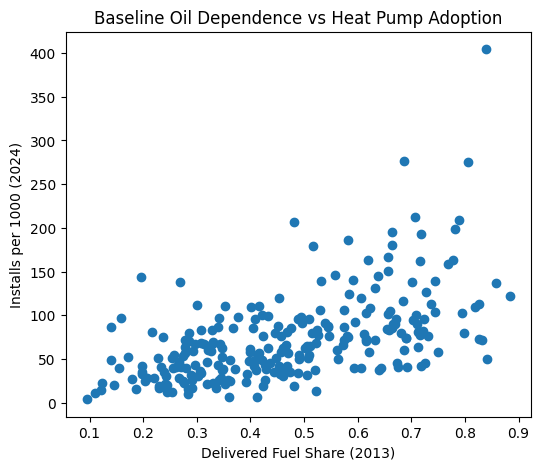

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.scatter(
    df_plot["delivered_share_2013"],
    df_plot["installs_per_1000_2024"]
)

plt.xlabel("Delivered Fuel Share (2013)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Baseline Oil Dependence vs Heat Pump Adoption")

plt.show()

In [42]:
corr = df_plot["delivered_share_2013"].corr(df_plot["installs_per_1000_2024"])
print("Correlation:", corr)

Correlation: 0.5546831362914153


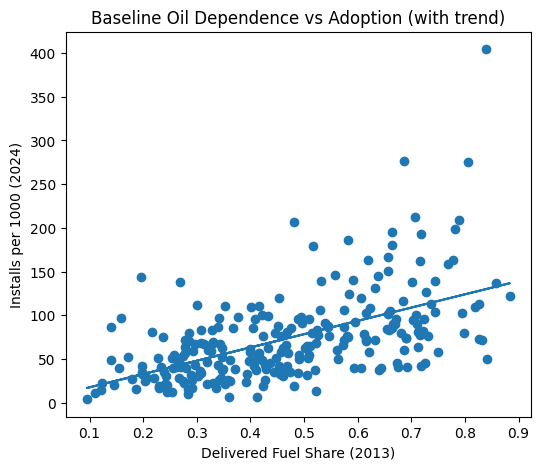

In [43]:
x = df_plot["delivered_share_2013"]
y = df_plot["installs_per_1000_2024"]

m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(6,5))

plt.scatter(x, y)
plt.plot(x, m*x + b)

plt.xlabel("Delivered Fuel Share (2013)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Baseline Oil Dependence vs Adoption (with trend)")

plt.show()

In [54]:
df_outliers = df[df["installs_per_1000_2024"] > 300]

df_outliers[[
    "municipality",
    "installs_per_1000_2024",
    "delivered_share_2013",
    "total_households_2024"
]].sort_values("installs_per_1000_2024", ascending=False)

,municipality,installs_per_1000_2024,delivered_share_2013,total_households_2024
299,truro,404.360753,0.838359,1009


In [55]:
df.sort_values("installs_per_1000_2024", ascending=False).head(10)[[
    "municipality",
    "installs_per_1000_2024",
    "delivered_share_2013",
    "total_households_2024"
]]

,municipality,installs_per_1000_2024,delivered_share_2013,total_households_2024
299,truro,404.360753,0.838359,1009
241,provincetown,276.245767,0.687027,2067
317,wellfleet,275.012083,0.805210,2069
229,pelham,212.686567,0.706087,536
89,edgartown,209.406495,0.788326,1786
86,eastham,206.839855,0.480728,3041
62,chilmark,198.952880,0.782209,573
153,leverett,195.224719,0.664894,712
326,west tisbury,192.585895,0.717151,1106
271,shutesbury,185.676393,0.581769,754


In [56]:
q1 = df["installs_per_1000_2024"].quantile(0.25)
q3 = df["installs_per_1000_2024"].quantile(0.75)
iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

df_outliers = df[df["installs_per_1000_2024"] > upper_bound]

df_outliers[[
    "municipality",
    "installs_per_1000_2024",
    "delivered_share_2013"
]]

,municipality,installs_per_1000_2024,delivered_share_2013
41,brewster,179.219117,0.515832
62,chilmark,198.952880,0.782209
86,eastham,206.839855,0.480728
89,edgartown,209.406495,0.788326
105,gill,180.277350,0.663701
153,leverett,195.224719,0.664894
229,pelham,212.686567,0.706087
241,provincetown,276.245767,0.687027
271,shutesbury,185.676393,0.581769
299,truro,404.360753,0.838359


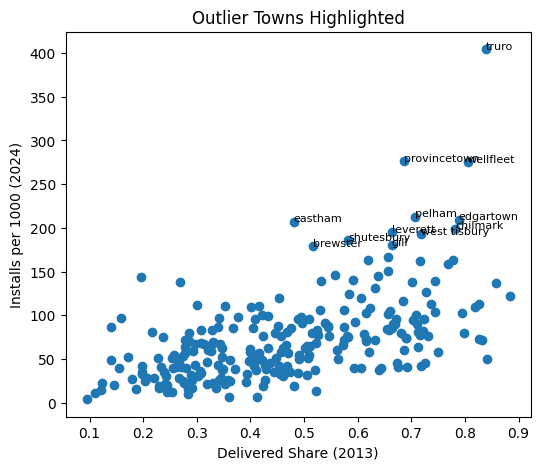

In [57]:


plt.figure(figsize=(6,5))

plt.scatter(
    df["delivered_share_2013"],
    df["installs_per_1000_2024"]
)

# label only outliers
for _, row in df_outliers.iterrows():
    plt.text(
        row["delivered_share_2013"],
        row["installs_per_1000_2024"],
        row["municipality"],
        fontsize=8
    )

plt.xlabel("Delivered Share (2013)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Outlier Towns Highlighted")

plt.show()

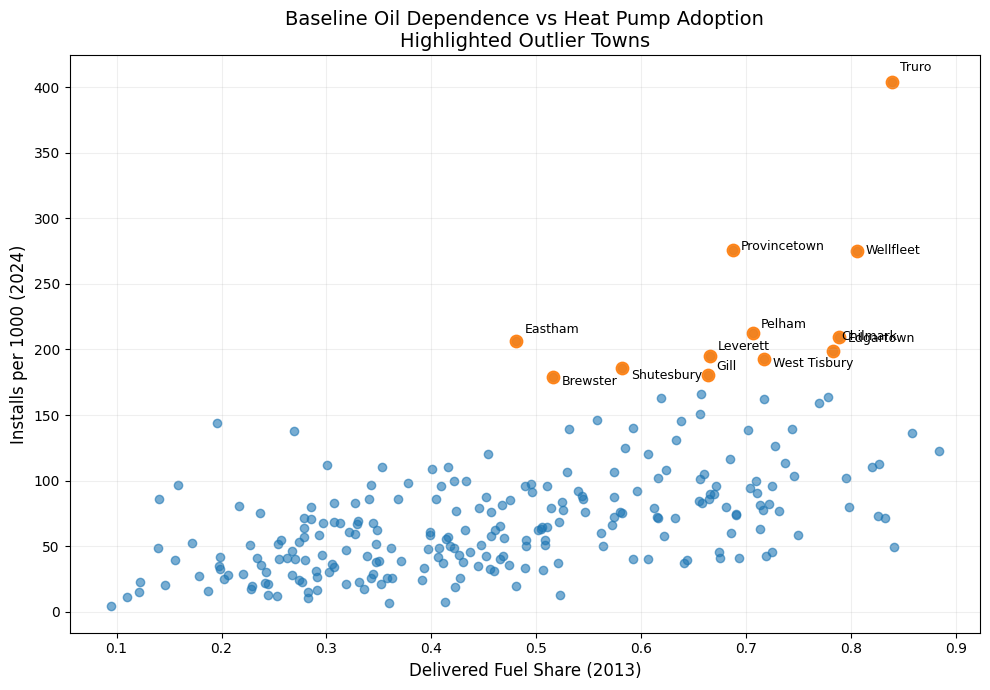

In [58]:
# outliers already created earlier
# df_outliers = ...

plt.figure(figsize=(10, 7))

# all towns
plt.scatter(
    df["delivered_share_2013"],
    df["installs_per_1000_2024"],
    alpha=0.6
)

# highlight outliers
plt.scatter(
    df_outliers["delivered_share_2013"],
    df_outliers["installs_per_1000_2024"],
    s=80,
    alpha=0.9
)

# manual offsets for labels
offsets = {
    "truro": (0.008, 8),
    "wellfleet": (0.008, -2),
    "provincetown": (0.008, 0),
    "eastham": (0.008, 6),
    "brewster": (0.008, -6),
    "pelham": (0.008, 4),
    "edgartown": (0.008, -4),
    "tisbury": (0.008, 6),
    "west tisbury": (0.008, -6),
    "chilmark": (0.008, 8),
    "shutesbury": (0.008, -8),
    "leverett": (0.008, 4)
}

for _, row in df_outliers.iterrows():
    town = row["municipality"]
    x = row["delivered_share_2013"]
    y = row["installs_per_1000_2024"]

    dx, dy = offsets.get(town, (0.008, 4))

    plt.annotate(
        town.title(),
        (x, y),
        xytext=(x + dx, y + dy),
        textcoords="data",
        fontsize=9
    )

plt.xlabel("Delivered Fuel Share (2013)", fontsize=12)
plt.ylabel("Installs per 1000 (2024)", fontsize=12)
plt.title("Baseline Oil Dependence vs Heat Pump Adoption\nHighlighted Outlier Towns", fontsize=14)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

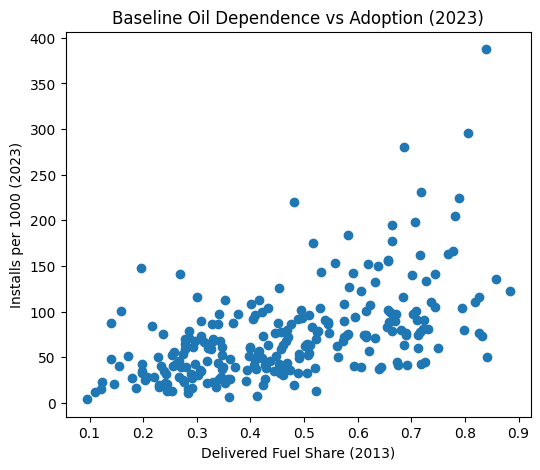

In [44]:
df_plot = df[[
    "delivered_share_2013",
    "installs_per_1000_2023"
]].dropna()

plt.figure(figsize=(6,5))

plt.scatter(
    df_plot["delivered_share_2013"],
    df_plot["installs_per_1000_2023"]
)

plt.xlabel("Delivered Fuel Share (2013)")
plt.ylabel("Installs per 1000 (2023)")
plt.title("Baseline Oil Dependence vs Adoption (2023)")

plt.show()

In [45]:
corr = df_plot["delivered_share_2013"].corr(df_plot["installs_per_1000_2023"])
print("Correlation:", corr)

Correlation: 0.5514810301076288


In [49]:
df["adoption_change"].mean()

np.float64(-0.7504325925553628)

In [50]:
df["household_change"] = (
    df["total_households_2024"] - df["total_households_2023"]
)

In [51]:
df["household_change"].mean()

np.float64(65.44729344729345)

In [52]:
(df["household_change"] > 0).sum()
(df["household_change"] < 0).sum()

np.int64(132)

In [53]:
df[["household_change", "adoption_change"]].corr()

,household_change,adoption_change
household_change,1.000000,-0.221232
adoption_change,-0.221232,1.000000


In [60]:
df["delivered_share_change_13_23"].mean()

np.float64(-0.042993029632705494)

In [61]:
df["delivered_share_change_13_24"].mean()

np.float64(-0.048200734877540306)

In [62]:
df["delivered_share_change_13_24"].median()

-0.0574530981364653

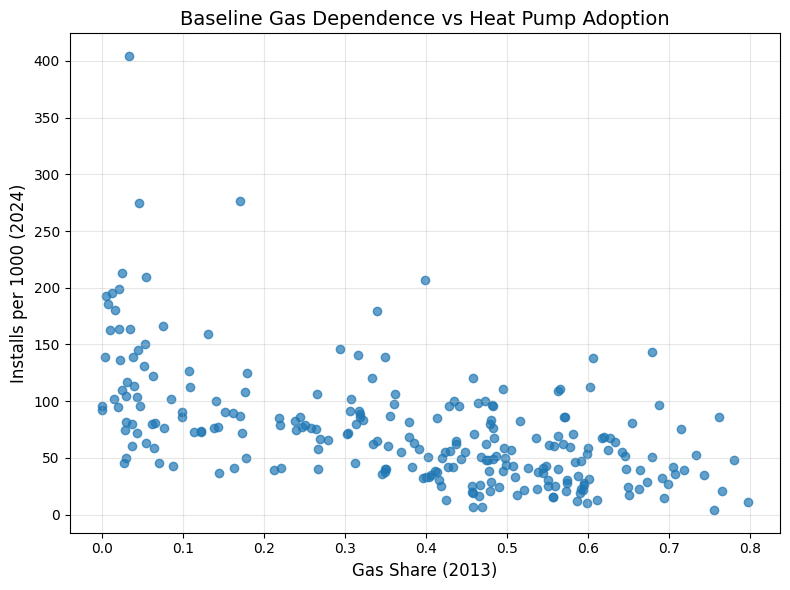

In [66]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["gas_share_2013"],
    df["installs_per_1000_2024"],
    alpha=0.7
)

plt.xlabel("Gas Share (2013)", fontsize=12)
plt.ylabel("Installs per 1000 (2024)", fontsize=12)
plt.title("Baseline Gas Dependence vs Heat Pump Adoption", fontsize=14)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [69]:
df_outliers = df[
    (df["installs_per_1000_2024"] > 200)
]

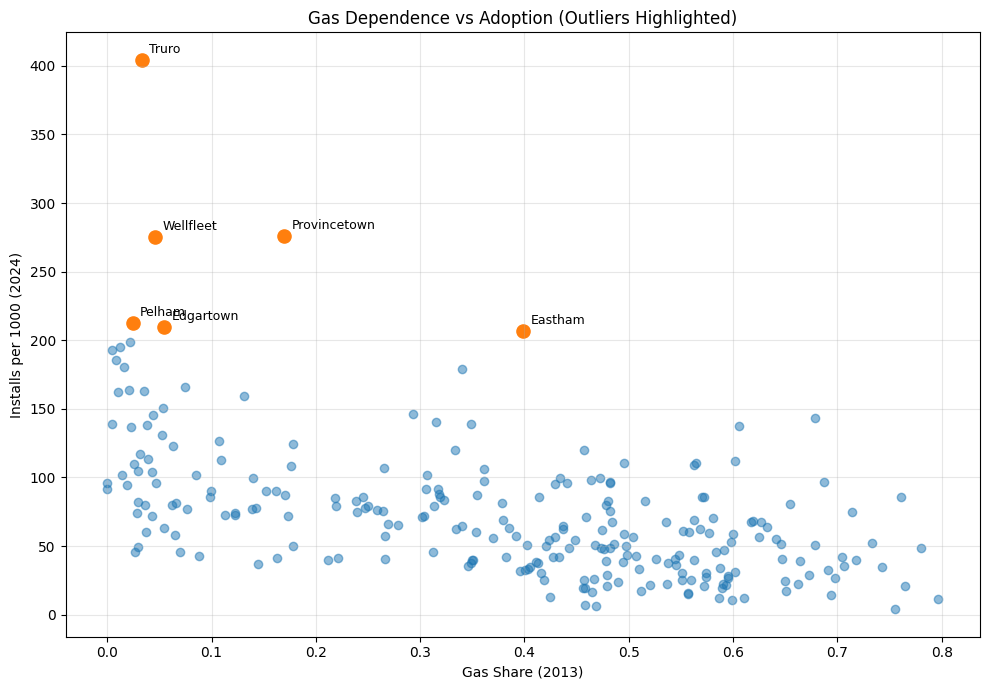

In [70]:
plt.figure(figsize=(10,7))

# all towns
plt.scatter(
    df["gas_share_2013"],
    df["installs_per_1000_2024"],
    alpha=0.5
)

# highlight outliers
plt.scatter(
    df_outliers["gas_share_2013"],
    df_outliers["installs_per_1000_2024"],
    s=90
)

# label outliers
for _, row in df_outliers.iterrows():
    plt.annotate(
        row["municipality"].title(),
        (row["gas_share_2013"], row["installs_per_1000_2024"]),
        xytext=(5,5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Gas Share (2013)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Gas Dependence vs Adoption (Outliers Highlighted)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [68]:
df_outliers = df[
    (df["installs_per_1000_2024"] > 200) &
    (df["gas_share_2013"] < 0.15)
]

df_outliers[[
    "municipality",
    "installs_per_1000_2024",
    "gas_share_2013",
    "delivered_share_2013",
    "total_households_2024"
]].sort_values("installs_per_1000_2024", ascending=False)

,municipality,installs_per_1000_2024,gas_share_2013,delivered_share_2013,total_households_2024
299,truro,404.360753,0.033776,0.838359,1009
317,wellfleet,275.012083,0.046181,0.805210,2069
229,pelham,212.686567,0.024348,0.706087,536
89,edgartown,209.406495,0.054852,0.788326,1786


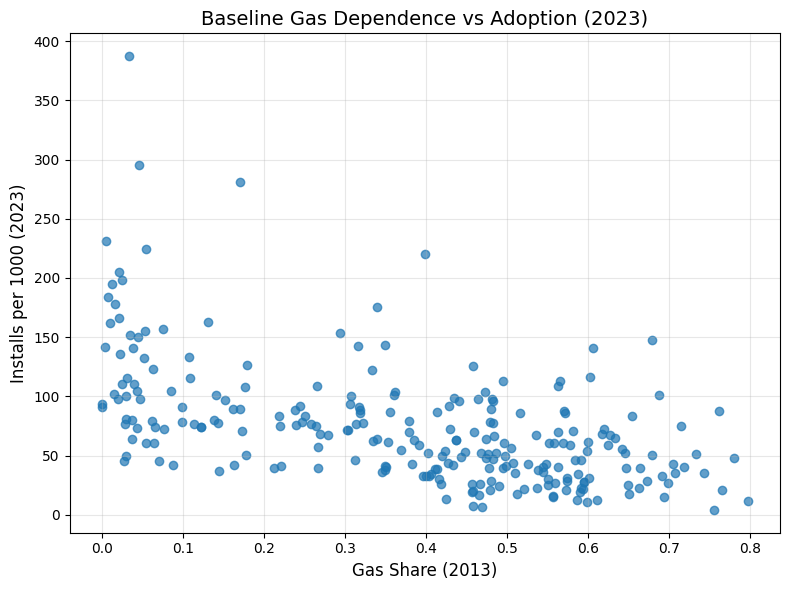

In [67]:
x = df["gas_share_2013"]
y = df["installs_per_1000_2023"]

plt.figure(figsize=(8,6))

plt.scatter(x, y, alpha=0.7)

# trend line
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b)

plt.xlabel("Gas Share (2013)", fontsize=12)
plt.ylabel("Installs per 1000 (2023)", fontsize=12)
plt.title("Baseline Gas Dependence vs Adoption (2023)", fontsize=14)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

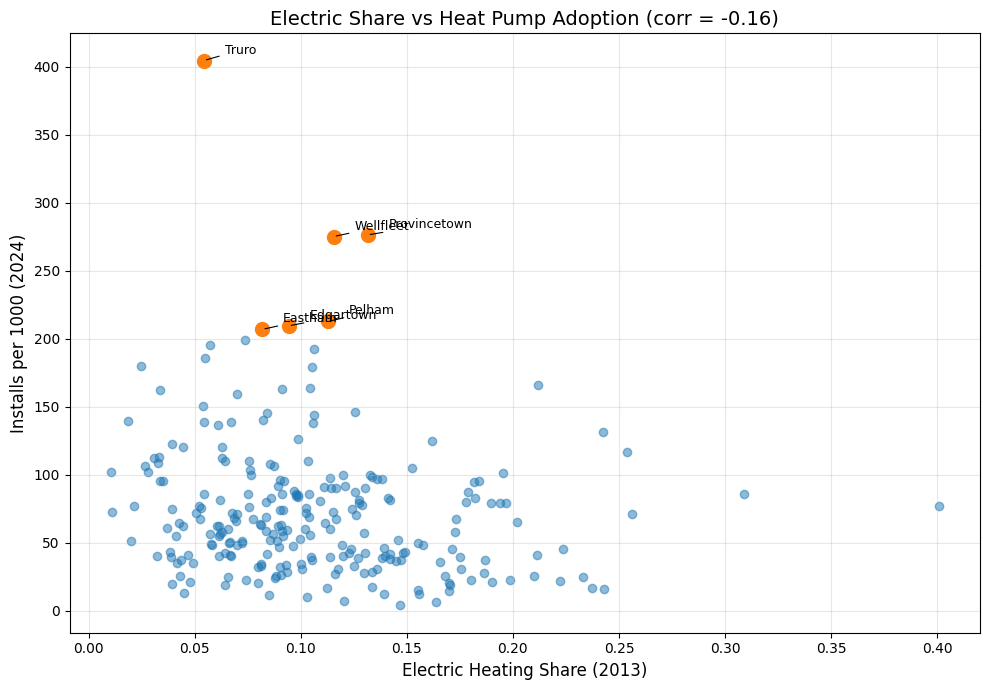

In [74]:
# define outliers (high adoption)
df_outliers = df[df["installs_per_1000_2024"] > 200]

x = df["electric_share_2013"]
y = df["installs_per_1000_2024"]

# trend line
m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(10,7))

# all points
plt.scatter(x, y, alpha=0.5)

# highlight outliers
plt.scatter(
    df_outliers["electric_share_2013"],
    df_outliers["installs_per_1000_2024"],
    s=100
)

# label outliers (with arrows)
for _, row in df_outliers.iterrows():
    plt.annotate(
        row["municipality"].title(),
        xy=(row["electric_share_2013"], row["installs_per_1000_2024"]),
        xytext=(15,5),
        textcoords="offset points",
        fontsize=9,
        arrowprops=dict(arrowstyle="-", lw=0.8)
    )

# plot trend line
plt.plot(x, m*x + b)

# correlation
corr = df[["electric_share_2013", "installs_per_1000_2024"]].corr().iloc[0,1]

# labels
plt.xlabel("Electric Heating Share (2013)", fontsize=12)
plt.ylabel("Installs per 1000 (2024)", fontsize=12)
plt.title(f"Electric Share vs Heat Pump Adoption (corr = {corr:.2f})", fontsize=14)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

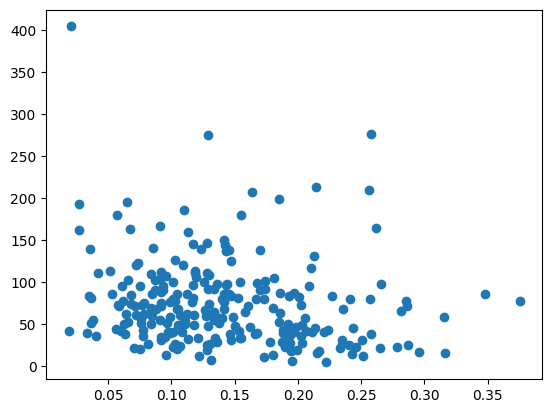

In [72]:
plt.scatter(
    df["electric_share_2024"],
    df["installs_per_1000_2024"]
)

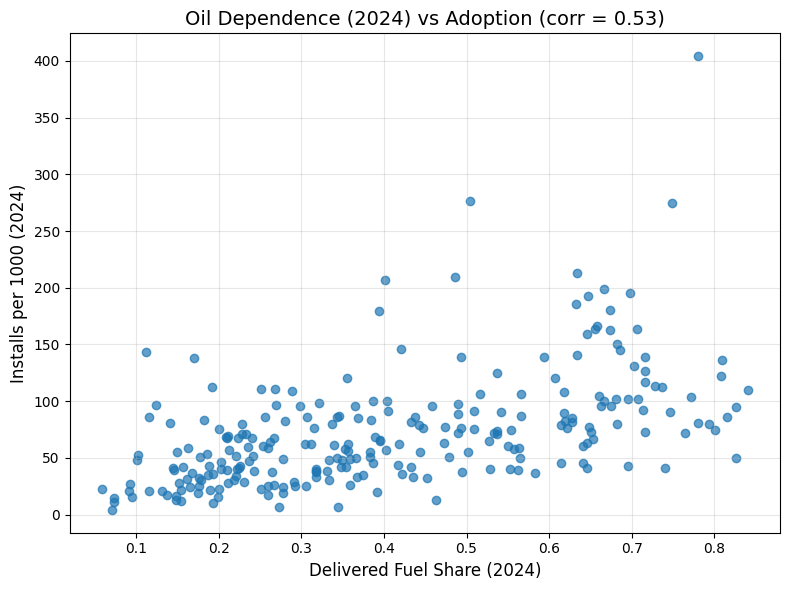

In [75]:

x = df["delivered_share_2024"]
y = df["installs_per_1000_2024"]

# trend line
m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(8,6))

plt.scatter(x, y, alpha=0.7)
plt.plot(x, m*x + b)

corr = df[["delivered_share_2024", "installs_per_1000_2024"]].corr().iloc[0,1]

plt.xlabel("Delivered Fuel Share (2024)", fontsize=12)
plt.ylabel("Installs per 1000 (2024)", fontsize=12)
plt.title(f"Oil Dependence (2024) vs Adoption (corr = {corr:.2f})", fontsize=14)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

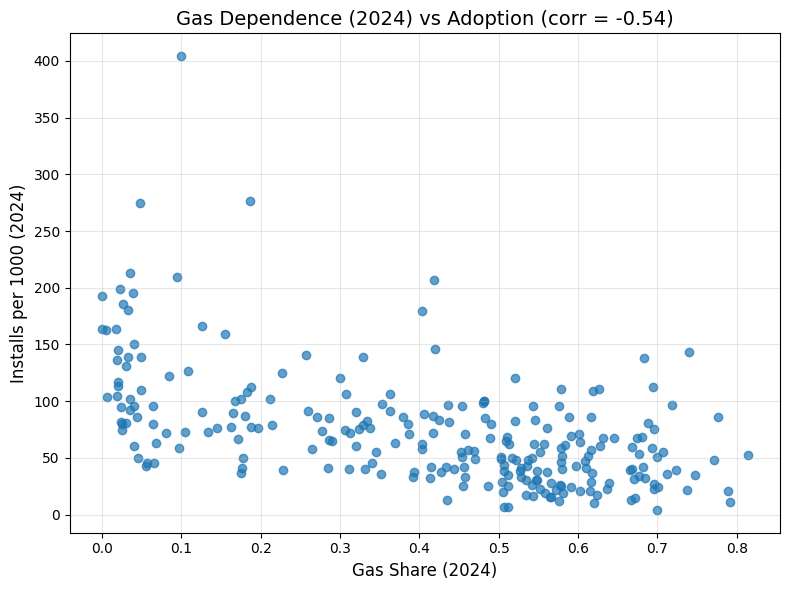

In [76]:
x = df["gas_share_2024"]
y = df["installs_per_1000_2024"]

# trend line
m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(8,6))

plt.scatter(x, y, alpha=0.7)
plt.plot(x, m*x + b)

corr = df[["gas_share_2024", "installs_per_1000_2024"]].corr().iloc[0,1]

plt.xlabel("Gas Share (2024)", fontsize=12)
plt.ylabel("Installs per 1000 (2024)", fontsize=12)
plt.title(f"Gas Dependence (2024) vs Adoption (corr = {corr:.2f})", fontsize=14)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2013.csv to elect_clean_2013.csv


In [2]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2023.csv to elect_clean_2023.csv


In [14]:
from google.colab import files
uploaded = files.upload()

Saving elec_clean_2024.csv to elec_clean_2024 (1).csv


In [15]:
from google.colab import files
uploaded = files.upload()

Saving fuel_full_2013_2023_2024.csv to fuel_full_2013_2023_2024.csv


In [8]:
import pandas as pd
elec_2013 = pd.read_csv("elect_clean_2013.csv")
elec_2023 = pd.read_csv("elect_clean_2023.csv")
elec_2024 = pd.read_csv("elec_clean_2024.csv")

In [10]:
elec_2013 = elec_2013[["municipality", "winter_summer_ratio"]]
elec_2023 = elec_2023[["municipality", "winter_summer_ratio"]]
elec_2024 = elec_2024[["Municipality", "winter_summer_ratio"]]

In [11]:
elec_2013 = elec_2013.rename(columns={"winter_summer_ratio": "wsr_2013"})
elec_2023 = elec_2023.rename(columns={"winter_summer_ratio": "wsr_2023"})
elec_2024 = elec_2024.rename(columns={"winter_summer_ratio": "wsr_2024"})

In [16]:
df = pd.read_csv("fuel_full_2013_2023_2024.csv")

In [19]:
df.columns = df.columns.str.lower().str.strip()
elec_2013.columns = elec_2013.columns.str.lower().str.strip()
elec_2023.columns = elec_2023.columns.str.lower().str.strip()
elec_2024.columns = elec_2024.columns.str.lower().str.strip()

In [20]:
for d in [df, elec_2013, elec_2023, elec_2024]:
    d["municipality"] = d["municipality"].str.strip().str.lower()

In [21]:
# Merge step by step
df = df.merge(elec_2013, on="municipality", how="left")
df = df.merge(elec_2023, on="municipality", how="left")
df = df.merge(elec_2024, on="municipality", how="left")

In [23]:
print(df.columns)

Index(['municipality', 'total_households_2023', 'electric_fuel_2023',
       'gas_fuel_2023', 'delivered_fuels_2023', 'electric_share_2023',
       'gas_share_2023', 'delivered_share_2023', 'installs_per_1000_2023',
       'total_households_2024', 'electric_fuel_2024', 'gas_fuel_2024',
       'delivered_fuels_2024', 'electric_share_2024', 'gas_share_2024',
       'delivered_share_2024', 'installs_per_1000_2024',
       'electric_share_change_23_24', 'gas_share_change_23_24',
       'delivered_share_change_23_24', 'adoption_change_23_24',
       'total_households_2013', 'electric_fuel_2013', 'gas_fuel_2013',
       'delivered_fuels_2013', 'electric_share_2013', 'gas_share_2013',
       'delivered_share_2013', 'delivered_share_change_13_23',
       'gas_share_change_13_23', 'electric_share_change_13_23',
       'delivered_share_change_13_24', 'gas_share_change_13_24',
       'electric_share_change_13_24', 'wsr_2013', 'wsr_2023', 'wsr_2024'],
      dtype='object')


In [24]:
analysis_df = df[[
    "municipality",
    "installs_per_1000_2024",
    "electric_share_2024",
    "gas_share_2024",
    "delivered_share_2024",
    "wsr_2013",
    "wsr_2023",
    "wsr_2024"
]]

In [25]:
analysis_df = analysis_df.dropna(subset=["installs_per_1000_2024", "wsr_2024"])

In [26]:
analysis_df[[
    "wsr_2013",
    "wsr_2023",
    "wsr_2024",
    "installs_per_1000_2024"
]].corr()

,wsr_2013,wsr_2023,wsr_2024,installs_per_1000_2024
wsr_2013,1.000000,0.749231,0.722810,0.126903
wsr_2023,0.749231,1.000000,0.962722,0.093207
wsr_2024,0.722810,0.962722,1.000000,0.246479
installs_per_1000_2024,0.126903,0.093207,0.246479,1.000000


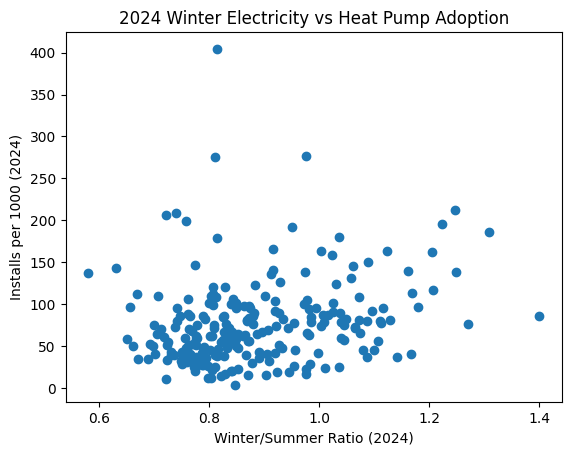

In [27]:
import matplotlib.pyplot as plt

plt.scatter(analysis_df["wsr_2024"], analysis_df["installs_per_1000_2024"])
plt.xlabel("Winter/Summer Ratio (2024)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("2024 Winter Electricity vs Heat Pump Adoption")
plt.show()

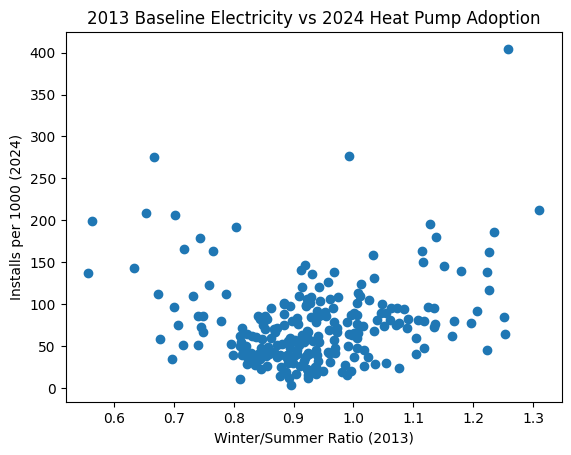

In [28]:
plt.scatter(analysis_df["wsr_2013"], analysis_df["installs_per_1000_2024"])
plt.xlabel("Winter/Summer Ratio (2013)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("2013 Baseline Electricity vs 2024 Heat Pump Adoption")
plt.show()

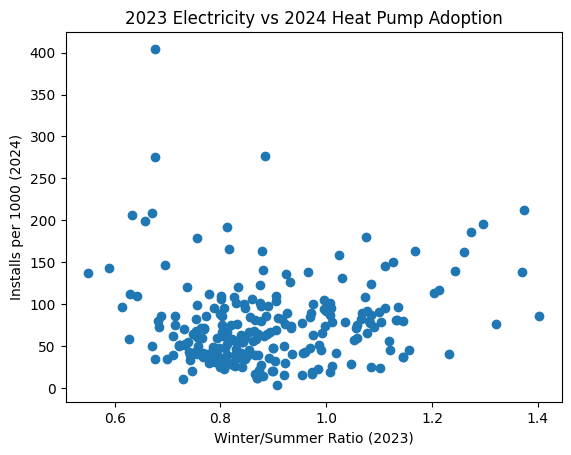

In [29]:
plt.scatter(analysis_df["wsr_2023"], analysis_df["installs_per_1000_2024"])
plt.xlabel("Winter/Summer Ratio (2023)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("2023 Electricity vs 2024 Heat Pump Adoption")
plt.show()

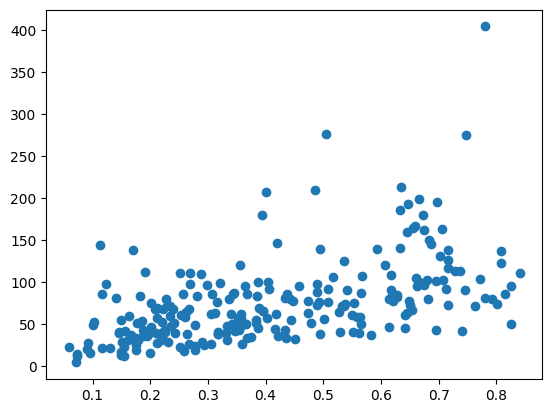

In [30]:
plt.scatter(analysis_df["delivered_share_2024"], analysis_df["installs_per_1000_2024"])

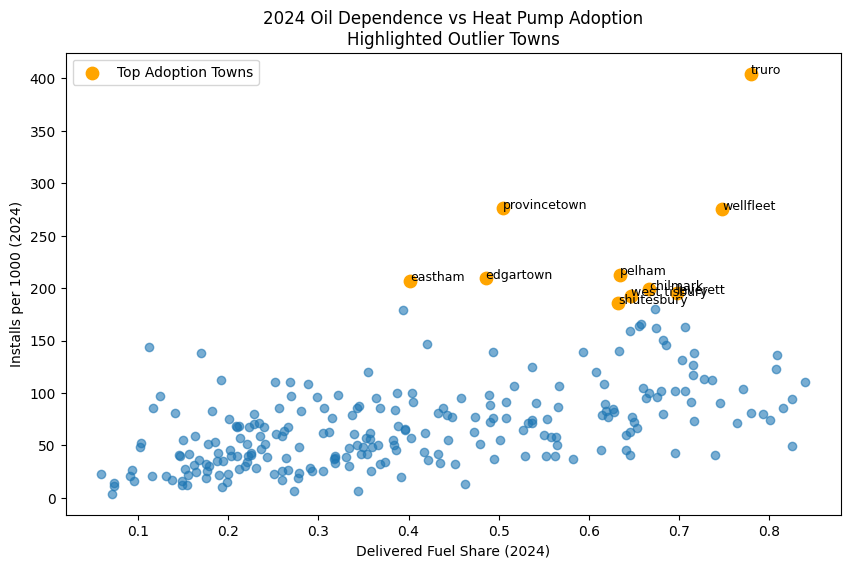

In [31]:
import matplotlib.pyplot as plt

# Base scatter
plt.figure(figsize=(10,6))
plt.scatter(df["delivered_share_2024"], df["installs_per_1000_2024"], alpha=0.6)

# --- Highlight top adoption towns ---
top_towns = df.nlargest(10, "installs_per_1000_2024")

plt.scatter(
    top_towns["delivered_share_2024"],
    top_towns["installs_per_1000_2024"],
    color="orange",
    s=80,
    label="Top Adoption Towns"
)

# --- Add labels ---
for _, row in top_towns.iterrows():
    plt.text(
        row["delivered_share_2024"],
        row["installs_per_1000_2024"],
        row["municipality"],
        fontsize=9
    )

# Labels & title
plt.xlabel("Delivered Fuel Share (2024)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("2024 Oil Dependence vs Heat Pump Adoption\nHighlighted Outlier Towns")
plt.legend()

plt.show()

In [32]:
df["fuel_change"] = df["delivered_share_2024"] - df["delivered_share_2013"]

# Sort by biggest change
fuel_shift_towns = df.sort_values("fuel_change", ascending=False)

fuel_shift_towns[["municipality", "delivered_share_2013", "delivered_share_2024", "fuel_change"]].head(10)

,municipality,delivered_share_2013,delivered_share_2024,fuel_change
312,washington,0.514563,0.740157,0.225594
84,east brookfield,0.574282,0.790850,0.216568
344,windsor,0.594366,0.750552,0.156186
110,granby,0.664704,0.815166,0.150462
107,goshen,0.591209,0.733333,0.142125
182,middlefield,0.596244,0.723684,0.127440
131,hinsdale,0.677419,0.803571,0.126152
90,egremont,0.699099,0.823640,0.124541
256,rutland,0.703704,0.825746,0.122042
183,middleton,0.440951,0.561160,0.120209


In [40]:
fuel_shift_towns.head(10)[[
    "municipality",
    "fuel_change",
    "installs_per_1000_2024"
]]

,municipality,fuel_change,installs_per_1000_2024
312,washington,0.225594,NaN
84,east brookfield,0.216568,NaN
344,windsor,0.156186,NaN
110,granby,0.150462,85.738906
107,goshen,0.142125,NaN
182,middlefield,0.127440,NaN
131,hinsdale,0.126152,NaN
90,egremont,0.124541,NaN
256,rutland,0.122042,94.505495
183,middleton,0.120209,NaN


In [41]:
valid_df = df.dropna(subset=["installs_per_1000_2024"])

In [42]:
valid_df.sort_values("fuel_change", ascending=False).head(10)

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,gas_share_change_13_24,electric_share_change_13_24,wsr_2013,wsr_2023,wsr_2024,fuel_change,rank_2013_proxy,rank_2024_proxy,rank_shift,abs_fuel_change
110,granby,2539,138,181,2048,0.054352,0.071288,0.806617,78.377314,2321,...,-0.054993,-0.044768,0.943088,0.885457,0.879322,0.150462,85.0,8.0,-77.0,0.150462
256,rutland,3091,320,101,2433,0.103526,0.032676,0.787124,97.379489,3185,...,0.004741,-0.087955,1.084226,0.995008,0.981924,0.122042,64.0,5.0,-59.0,0.122042
134,holland,1164,171,43,759,0.146907,0.036942,0.652062,93.642612,1187,...,0.035383,0.007952,1.206816,1.076475,1.095827,0.117693,131.0,56.0,-75.0,0.117693
139,hubbardston,1630,144,44,1276,0.088344,0.026994,0.782822,76.687117,1686,...,-0.004055,-0.021982,1.051373,0.997155,1.003913,0.110784,68.0,12.0,-56.0,0.110784
81,dunstable,1135,81,282,740,0.071366,0.248458,0.651982,100.440529,1117,...,-0.095598,0.054772,0.884305,0.828467,0.799272,0.091731,115.0,57.0,-58.0,0.091731
119,hampden,1965,141,694,1015,0.071756,0.353181,0.516539,54.961832,1945,...,-0.024510,-0.028205,0.918295,0.836969,0.820700,0.088277,233.0,154.0,-79.0,0.088277
224,otis,751,55,14,515,0.073236,0.018642,0.685752,151.797603,698,...,-0.017634,-0.023875,1.114186,1.168161,1.123484,0.087730,113.0,58.0,-55.0,0.087730
322,west brookfield,1627,165,286,1050,0.101414,0.175784,0.645360,68.223725,1675,...,-0.097887,0.057199,1.007695,0.992617,0.977382,0.081019,145.0,88.0,-57.0,0.081019
286,sturbridge,4031,865,100,2840,0.214587,0.024808,0.704540,132.473332,4072,...,-0.021400,-0.029719,1.034851,1.029185,1.057117,0.070520,105.0,60.0,-45.0,0.070520
266,sheffield,1448,86,70,1054,0.059392,0.048343,0.727901,73.895028,1319,...,-0.035692,-0.025457,1.061127,1.133444,1.072785,0.067141,57.0,19.0,-38.0,0.067141


In [33]:
fuel_shift_towns.tail(10)[["municipality", "delivered_share_2013", "delivered_share_2024", "fuel_change"]]

,municipality,delivered_share_2013,delivered_share_2024,fuel_change
167,marblehead,0.351916,0.189890,-0.162026
120,hancock,0.725100,0.561056,-0.164043
304,wakefield,0.527568,0.353771,-0.173797
241,provincetown,0.687027,0.504596,-0.182431
196,nantucket,0.748833,0.563595,-0.185238
310,warren,0.543562,0.344210,-0.199353
46,brookline,0.318821,0.115779,-0.203041
60,chesterfield,0.715447,0.498783,-0.216664
18,avon,0.600602,0.374490,-0.226112
89,edgartown,0.788326,0.485442,-0.302884


In [44]:
fuel_shift_towns.tail(10)[[
    "municipality",
    "fuel_change",
    "installs_per_1000_2024"
]]

,municipality,fuel_change,installs_per_1000_2024
167,marblehead,-0.162026,21.474243
120,hancock,-0.164043,NaN
304,wakefield,-0.173797,NaN
241,provincetown,-0.182431,276.245767
196,nantucket,-0.185238,58.263519
310,warren,-0.199353,NaN
46,brookline,-0.203041,20.988147
60,chesterfield,-0.216664,NaN
18,avon,-0.226112,NaN
89,edgartown,-0.302884,209.406495


In [49]:
tourist_towns = [
    "provincetown", "truro", "wellfleet",
    "nantucket", "edgartown", "oak bluffs", "west tisbury"
]

In [50]:
non_tourist = df[~df["municipality"].isin(tourist_towns)]

In [51]:
high_adoption_threshold = 100
low_fuel_change_threshold = 0.08

In [52]:
clean_signal = non_tourist[
    (non_tourist["installs_per_1000_2024"] > high_adoption_threshold) &
    (abs(non_tourist["fuel_change"]) < low_fuel_change_threshold)
]

In [53]:
clean_signal[[
    "municipality",
    "installs_per_1000_2024",
    "delivered_share_2013",
    "delivered_share_2024",
    "fuel_change",
    "gas_share_2024"
]].sort_values("installs_per_1000_2024", ascending=False)

,municipality,installs_per_1000_2024,delivered_share_2013,delivered_share_2024,fuel_change,gas_share_2024
229,pelham,212.686567,0.706087,0.634328,-0.071759,0.035448
86,eastham,206.839855,0.480728,0.401513,-0.079215,0.418612
153,leverett,195.224719,0.664894,0.698034,0.033140,0.039326
271,shutesbury,185.676393,0.581769,0.632626,0.050857,0.026525
105,gill,180.277350,0.663701,0.673344,0.009643,0.032357
47,buckland,162.383178,0.717113,0.674065,-0.043048,0.004673
29,bernardston,150.490731,0.656000,0.682661,0.026661,0.040349
216,northfield,145.468393,0.637795,0.686215,0.048419,0.019802
268,sherborn,140.339426,0.592151,0.633159,0.041008,0.256527
51,carlisle,139.076577,0.530659,0.493806,-0.036853,0.329392


In [54]:
df[
    (df["delivered_share_2013"] > 0.75) &
    (df["installs_per_1000_2024"] > 200)
][["municipality"]]

,municipality
89,edgartown
299,truro
317,wellfleet


In [55]:
top_adoption = df.nlargest(10, "installs_per_1000_2024")
top_adoption["municipality"]

,municipality
299,truro
241,provincetown
317,wellfleet
229,pelham
89,edgartown
86,eastham
62,chilmark
153,leverett
326,west tisbury
271,shutesbury


In [56]:
exclude_towns = [
    "truro", "provincetown", "wellfleet", "pelham",
    "edgartown", "eastham", "chilmark", "leverett",
    "west tisbury", "shutesbury"
]

In [57]:
df_clean = df[~df["municipality"].isin(exclude_towns)]

In [58]:
df_clean["municipality"].isin(exclude_towns).sum()

np.int64(0)

In [59]:
analysis_clean = df_clean.dropna(subset=["installs_per_1000_2024"])

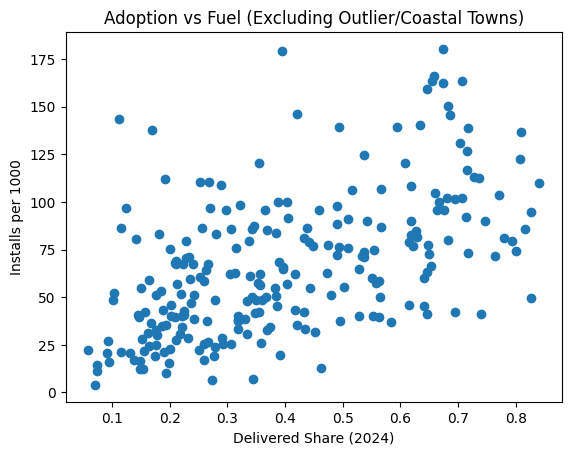

In [60]:
import matplotlib.pyplot as plt

plt.scatter(
    analysis_clean["delivered_share_2024"],
    analysis_clean["installs_per_1000_2024"]
)

plt.xlabel("Delivered Share (2024)")
plt.ylabel("Installs per 1000")
plt.title("Adoption vs Fuel (Excluding Outlier/Coastal Towns)")
plt.show()

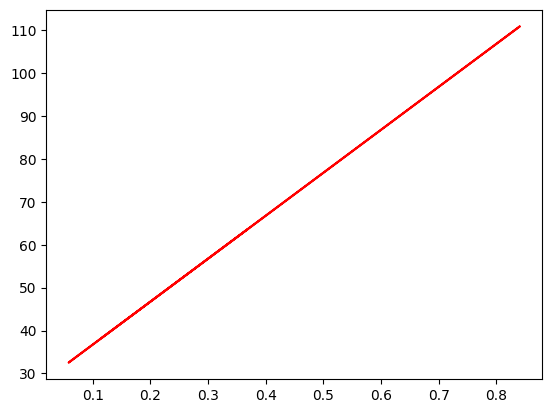

In [61]:
import numpy as np

x = analysis_clean["delivered_share_2024"]
y = analysis_clean["installs_per_1000_2024"]

m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color="red")

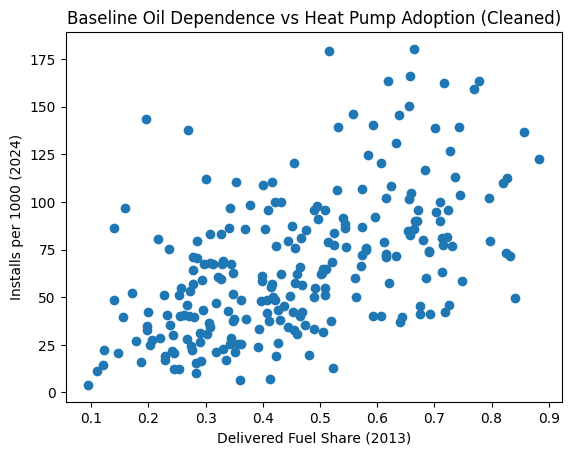

In [62]:
plt.scatter(
    analysis_clean["delivered_share_2013"],
    analysis_clean["installs_per_1000_2024"]
)

plt.xlabel("Delivered Fuel Share (2013)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Baseline Oil Dependence vs Heat Pump Adoption (Cleaned)")
plt.show()

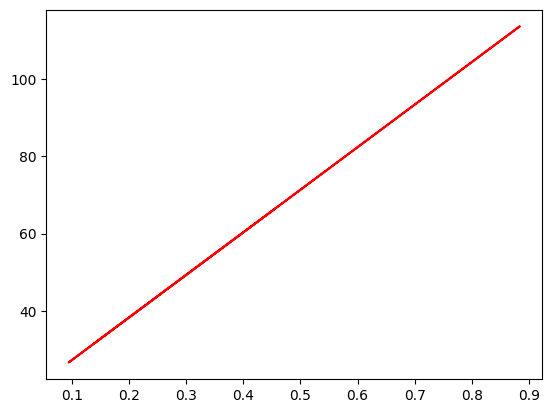

In [63]:
import numpy as np

x = analysis_clean["delivered_share_2013"]
y = analysis_clean["installs_per_1000_2024"]

m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color="red")

In [48]:
df[df["municipality"] == "truro"][[
    "delivered_share_2013",
    "delivered_share_2024",
    "fuel_change",
    "installs_per_1000_2024"
]]

,delivered_share_2013,delivered_share_2024,fuel_change,installs_per_1000_2024
299,0.838359,0.77998,-0.058379,404.360753


In [34]:
df["rank_2013_proxy"] = df["delivered_share_2013"].rank(ascending=False)
df["rank_2024_proxy"] = df["delivered_share_2024"].rank(ascending=False)

df["rank_shift"] = df["rank_2024_proxy"] - df["rank_2013_proxy"]

In [35]:
df.sort_values("rank_shift", ascending=False)[
    ["municipality", "rank_2013_proxy", "rank_2024_proxy", "rank_shift"]
].head(10)

,municipality,rank_2013_proxy,rank_2024_proxy,rank_shift
89,edgartown,22.0,164.0,142.0
60,chesterfield,54.0,155.0,101.0
196,nantucket,33.0,130.0,97.0
120,hancock,44.0,133.0,89.0
68,conway,36.0,122.0,86.0
241,provincetown,70.0,153.0,83.0
18,avon,127.0,206.0,79.0
308,ware,45.0,116.0,71.0
28,berlin,69.0,140.0,71.0
310,warren,156.0,227.0,71.0


In [36]:
df.sort_values("rank_shift")[
    ["municipality", "rank_2013_proxy", "rank_2024_proxy", "rank_shift"]
].head(10)

,municipality,rank_2013_proxy,rank_2024_proxy,rank_shift
312,washington,170.0,37.0,-133.0
84,east brookfield,141.0,15.0,-126.0
344,windsor,133.0,28.0,-105.0
107,goshen,136.0,42.0,-94.0
183,middleton,218.0,132.0,-86.0
128,hawley,248.0,165.0,-83.0
182,middlefield,130.0,50.0,-80.0
119,hampden,233.0,154.0,-79.0
110,granby,85.0,8.0,-77.0
134,holland,131.0,56.0,-75.0


In [37]:
df.sort_values("adoption_change_23_24", ascending=False)[
    ["municipality", "installs_per_1000_2023", "installs_per_1000_2024", "adoption_change_23_24"]
].head(10)

,municipality,installs_per_1000_2023,installs_per_1000_2024,adoption_change_23_24
299,truro,387.464387,404.360753,16.896366
229,pelham,198.606272,212.686567,14.080295
224,otis,151.797603,163.323782,11.526179
220,oak bluffs,156.492248,166.152263,9.660015
110,granby,78.377314,85.738906,7.361592
266,sheffield,73.895028,81.122062,7.227035
275,southampton,77.516234,83.442551,5.926318
24,belchertown,100.015603,104.635978,4.620375
43,brimfield,91.277890,95.744681,4.466790
269,shirley,74.875208,79.051383,4.176175


In [38]:
df["abs_fuel_change"] = abs(df["fuel_change"])

interesting = df.sort_values(["abs_fuel_change", "adoption_change_23_24"], ascending=False)

interesting[[
    "municipality",
    "fuel_change",
    "adoption_change_23_24"
]].head(10)

,municipality,fuel_change,adoption_change_23_24
89,edgartown,-0.302884,-15.083301
18,avon,-0.226112,NaN
312,washington,0.225594,NaN
60,chesterfield,-0.216664,NaN
84,east brookfield,0.216568,NaN
46,brookline,-0.203041,-0.290795
310,warren,-0.199353,NaN
196,nantucket,-0.185238,-2.354548
241,provincetown,-0.182431,-4.481863
304,wakefield,-0.173797,NaN


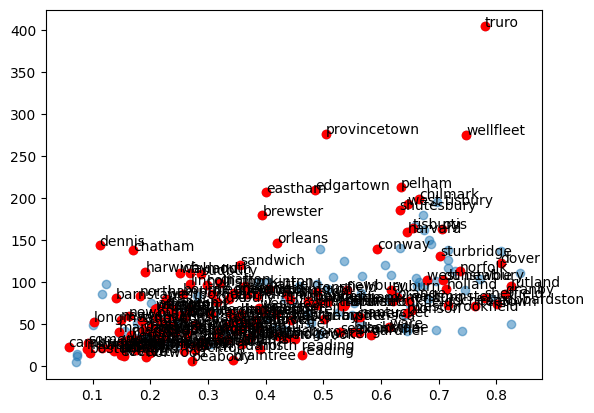

In [39]:
shifted = df[abs(df["fuel_change"]) > 0.05]

plt.scatter(df["delivered_share_2024"], df["installs_per_1000_2024"], alpha=0.5)
plt.scatter(shifted["delivered_share_2024"], shifted["installs_per_1000_2024"], color="red")

for _, row in shifted.iterrows():
    plt.text(row["delivered_share_2024"], row["installs_per_1000_2024"], row["municipality"])

plt.show()